In [1]:
# ============================================================ 
# CELL 1 — LONGFORMER + EMOTION-BASED 
# ============================================================ 

import os
import gc
import json
import random
import warnings
import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED) 
np.random.seed(SEED) 
torch.manual_seed(SEED) 

if torch.cuda.is_available(): 
    torch.cuda.manual_seed_all(SEED) 

device = torch.device( 
    "cuda" if torch.cuda.is_available() else "cpu" 
) 

print("=" * 60) 
print("LONGFORMER + EMOTION-BASED")
print("=" * 60)

print()
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

MODEL_NAME = "allenai/longformer-base-4096"
EXPERIMENT_NAME = "Longformer + Emotion-Based"
CLEANING_METHOD = "Emotion-Based"

MAX_LENGTH = 512
METADATA_DIM = 53
FREEZE_TRANSFORMER = True

BASE_RESULT_DIR = (
    "/kaggle/working/"
    "longformer_emotion"
)

RESULT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "results"
)

CHECKPOINT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "checkpoints"
)

BACKUP_DIR = os.path.join(
    BASE_RESULT_DIR,
    "backup"
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    BACKUP_DIR,
    exist_ok=True
)

EMOTION_MODEL_NAME = (
    "cardiffnlp/"
    "twitter-roberta-base-emotion-latest"
)

EMOTION_LABELS = [
    "anger",
    "anticipation",
    "disgust",
    "fear",
    "joy",
    "love",
    "optimism",
    "pessimism",
    "sadness",
    "surprise",
    "trust"
]

assert len(
    EMOTION_LABELS
) == 11

print()
print("Model:", MODEL_NAME)
print("Cleaning:", CLEANING_METHOD)
print("Context length:", MAX_LENGTH)
print("Metadata features:", METADATA_DIM)
print("Transformer frozen:", FREEZE_TRANSFORMER)
print("Seed:", SEED)

print()
print("=" * 60)
print("EMOTION MODEL")
print("=" * 60)

print(
    "Emotion model:",
    EMOTION_MODEL_NAME
)

print()
print("Emotion labels:")

for i, label in enumerate(
    EMOTION_LABELS,
    start=1
):

    print(
        f"{i:02d}. {label}"
    )

print()
print(
    "Number of emotion features:",
    11
)

print()
print("=" * 60)
print("LONGFORMER CONFIGURATION")
print("=" * 60)

print(
    "Base encoder: Longformer"
)

print(
    "Pretrained model:",
    MODEL_NAME
)

print(
    "Backbone training: FROZEN"
)

print(
    "Downstream classifier: TRAINABLE"
)

print(
    "Metadata branch: TRAINABLE"
)

print(
    "Emotion features: 11"
)

config = {
    "experiment_name":
        EXPERIMENT_NAME,

    "model_name":
        MODEL_NAME,

    "cleaning_method":
        CLEANING_METHOD,

    "context_length":
        MAX_LENGTH,

    "metadata_features":
        METADATA_DIM,

    "transformer_frozen":
        FREEZE_TRANSFORMER,

    "seed":
        SEED,

    "emotion_model":
        EMOTION_MODEL_NAME,

    "emotion_labels":
        EMOTION_LABELS
}

with open(
    os.path.join(
        RESULT_DIR,
        "experiment_config.json"
    ),
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print()
print("=" * 60)
print("CELL 1 COMPLETE")
print("=" * 60)

print(
    "✓ Longformer selected"
)

print(
    "✓ Emotion-Based cleaning selected"
)

print(
    "✓ Emotion model locked"
)

print(
    "✓ 11 emotion labels defined"
)

print(
    "✓ Context length = 512"
)

print(
    "✓ Metadata dimension = 53"
)

print(
    "✓ Transformer backbone = FROZEN"
)

print(
    "✓ Downstream layers = TRAINABLE"
)

print(
    "✓ Random seed = 42"
)

print(
    "✓ Result directory created"
)

print(
    "✓ Checkpoint directory created"
)

print(
    "✓ Backup directory created"
)

print(
    "✓ Experiment configuration saved"
)

print(
    "✓ Previous experiment outputs untouched"
)

LONGFORMER + EMOTION-BASED

Device: cuda
GPU: Tesla T4
CUDA: 12.8

Model: allenai/longformer-base-4096
Cleaning: Emotion-Based
Context length: 512
Metadata features: 53
Transformer frozen: True
Seed: 42

EMOTION MODEL
Emotion model: cardiffnlp/twitter-roberta-base-emotion-latest

Emotion labels:
01. anger
02. anticipation
03. disgust
04. fear
05. joy
06. love
07. optimism
08. pessimism
09. sadness
10. surprise
11. trust

Number of emotion features: 11

LONGFORMER CONFIGURATION
Base encoder: Longformer
Pretrained model: allenai/longformer-base-4096
Backbone training: FROZEN
Downstream classifier: TRAINABLE
Metadata branch: TRAINABLE
Emotion features: 11

CELL 1 COMPLETE
✓ Longformer selected
✓ Emotion-Based cleaning selected
✓ Emotion model locked
✓ 11 emotion labels defined
✓ Context length = 512
✓ Metadata dimension = 53
✓ Transformer backbone = FROZEN
✓ Downstream layers = TRAINABLE
✓ Random seed = 42
✓ Result directory created
✓ Checkpoint directory created
✓ Backup directory create

In [2]:
# ============================================================
# CELL 2 — LONGFORMER + EMOTION-BASED
# ============================================================

print("=" * 60)
print("LONGFORMER + EMOTION-BASED — LOADING EXACT USER-LEVEL SPLIT")
print("=" * 60)

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "mddl-experiment-1-splits"
)

TRAIN_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_train_raw.pkl"
)

VAL_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_val_raw.pkl"
)

TEST_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_test_raw.pkl"
)

print()
print("TRAIN:", TRAIN_PATH)
print("VAL:  ", VAL_PATH)
print("TEST: ", TEST_PATH)

assert os.path.exists(TRAIN_PATH)
assert os.path.exists(VAL_PATH)
assert os.path.exists(TEST_PATH)

print()
print("✓ All split files found")

train_df = pd.read_pickle(TRAIN_PATH)
val_df = pd.read_pickle(VAL_PATH)
test_df = pd.read_pickle(TEST_PATH)

print()
print("=" * 60)
print("SPLIT SHAPES")
print("=" * 60)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

assert train_df.shape == (6135, 82)
assert val_df.shape == (767, 82)
assert test_df.shape == (767, 82)

print()
print("=" * 60)
print("REQUIRED COLUMN CHECK")
print("=" * 60)

required_columns = [
    "user_id",
    "username",
    "label",
    "timeline_text"
]

for column in required_columns:
    assert column in train_df.columns
    assert column in val_df.columns
    assert column in test_df.columns
    print("✓", column)

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_users = set(train_df["user_id"])
val_users = set(val_df["user_id"])
test_users = set(test_df["user_id"])

print(
    "Train unique users:",
    train_df["user_id"].nunique()
)

print(
    "Validation unique users:",
    val_df["user_id"].nunique()
)

print(
    "Test unique users:",
    test_df["user_id"].nunique()
)

assert train_df["user_id"].is_unique
assert val_df["user_id"].is_unique
assert test_df["user_id"].is_unique

print(
    "TRAIN ↔ VAL:",
    len(train_users & val_users)
)

print(
    "TRAIN ↔ TEST:",
    len(train_users & test_users)
)

print(
    "VAL ↔ TEST:",
    len(val_users & test_users)
)

assert len(train_users & val_users) == 0
assert len(train_users & test_users) == 0
assert len(val_users & test_users) == 0

print()
print("✓ No duplicate users")
print("✓ No cross-split overlap")

print()
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    train_df["label"]
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")
print(
    val_df["label"]
    .value_counts()
    .sort_index()
)

print()
print("TEST:")
print(
    test_df["label"]
    .value_counts()
    .sort_index()
)

assert (
    train_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {0: 4122, 1: 2013}
)

assert (
    val_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {0: 515, 1: 252}
)

assert (
    test_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {0: 516, 1: 251}
)

print()
print("=" * 60)
print("TIMELINE TEXT CHECK")
print("=" * 60)

train_null = int(
    train_df["timeline_text"].isna().sum()
)

val_null = int(
    val_df["timeline_text"].isna().sum()
)

test_null = int(
    test_df["timeline_text"].isna().sum()
)

print(
    "TRAIN null timeline texts:",
    train_null
)

print(
    "VALIDATION null timeline texts:",
    val_null
)

print(
    "TEST null timeline texts:",
    test_null
)

assert train_null == 0
assert val_null == 0
assert test_null == 0

print()
print("=" * 60)
print("CELL 2 COMPLETE")
print("=" * 60)

print("✓ Exact user-level split restored")
print("✓ TRAIN = 6135")
print("✓ VALIDATION = 767")
print("✓ TEST = 767")
print("✓ Same labels as previous experiments")
print("✓ No duplicate users")
print("✓ No cross-split user overlap")
print("✓ Timeline text available")

LONGFORMER + EMOTION-BASED — LOADING EXACT USER-LEVEL SPLIT

TRAIN: /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_train_raw.pkl
VAL:   /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_val_raw.pkl
TEST:  /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_test_raw.pkl

✓ All split files found

SPLIT SHAPES
Train: (6135, 82)
Validation: (767, 82)
Test: (767, 82)

REQUIRED COLUMN CHECK
✓ user_id
✓ username
✓ label
✓ timeline_text

USER-LEVEL INTEGRITY
Train unique users: 6135
Validation unique users: 767
Test unique users: 767
TRAIN ↔ VAL: 0
TRAIN ↔ TEST: 0
VAL ↔ TEST: 0

✓ No duplicate users
✓ No cross-split overlap

LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

TIMELINE TEXT CHECK
TRAIN null timeline texts: 0
VALIDATION null timeline texts: 0
TEST null timeline texts: 0

CE

In [3]:
# ============================================================
# CELL 3 — LONGFORMER + EMOTION-BASED
# ============================================================

print("=" * 60)
print("LONGFORMER + EMOTION-BASED — EXACT D1 ANCHOR DETECTION")
print("=" * 60)

import os
import re
import json
import glob
from collections import defaultdict

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "depression-detection-mddl-final-pbl/"
    "Dataset_MDDL"
)

D1_TIMELINE_DIR = os.path.join(
    DATASET_ROOT,
    "labeled",
    "positive",
    "data",
    "timeline"
)

assert os.path.exists(D1_TIMELINE_DIR)

d1_timeline_files = glob.glob(
    os.path.join(D1_TIMELINE_DIR, "*.json")
)

print()
print("D1 timeline files found:", len(d1_timeline_files))

assert len(d1_timeline_files) == 2626

REFINED_ANCHOR_PATTERNS = [
    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",
    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",
    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depression\b",
    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",
    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",
    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",
    r"\bi\s+have\s+(?:major\s+)?depression\b",
    r"\bi\s+suffer\s+from\s+(?:major\s+)?depression\b",
    r"\bi\s+(?:was|am|'m)\s+diagnosed\b.{0,80}\bdepress",
    r"\b(?:my|a)\s+(?:doctor|psychiatrist)\s+(?:has\s+)?diagnosed\s+me\b.{0,80}\bdepress"
]

EXCLUSION_PATTERNS = [
    r"\bmy\s+friend\s+(?:was|is|has\s+been)\s+diagnosed",
    r"\bmy\s+sister\s+(?:was|is|has\s+been)\s+diagnosed",
    r"\bmy\s+brother\s+(?:was|is|has\s+been)\s+diagnosed",
    r"\bmy\s+mother\s+(?:was|is|has\s+been)\s+diagnosed",
    r"\bmy\s+father\s+(?:was|is|has\s+been)\s+diagnosed",
    r"\bmy\s+answer\s+to\s*:",
    r"\banswer\s+to\s*:",
    r"\bquestion\s*:",
    r"\bq\s*:"
]

anchor_patterns = [
    re.compile(
        p,
        re.IGNORECASE | re.DOTALL
    )
    for p in REFINED_ANCHOR_PATTERNS
]

exclusion_patterns = [
    re.compile(
        p,
        re.IGNORECASE | re.DOTALL
    )
    for p in EXCLUSION_PATTERNS
]


def is_refined_anchor_tweet(text):
    if text is None:
        return False

    text = str(text).strip()

    if not text:
        return False

    for pattern in exclusion_patterns:
        if pattern.search(text):
            return False

    for pattern in anchor_patterns:
        if pattern.search(text):
            return True

    return False


train_positive_users = set(
    train_df.loc[
        train_df["label"] == 1,
        "username"
    ].astype(str)
)

val_positive_users = set(
    val_df.loc[
        val_df["label"] == 1,
        "username"
    ].astype(str)
)

test_positive_users = set(
    test_df.loc[
        test_df["label"] == 1,
        "username"
    ].astype(str)
)

all_positive_users = (
    train_positive_users
    | val_positive_users
    | test_positive_users
)

print()
print("=" * 60)
print("POSITIVE USERS BY SPLIT")
print("=" * 60)

print("TRAIN:", len(train_positive_users))
print("VALIDATION:", len(val_positive_users))
print("TEST:", len(test_positive_users))

assert len(train_positive_users) == 2013
assert len(val_positive_users) == 252
assert len(test_positive_users) == 251
assert len(all_positive_users) == 2516


timeline_files_by_user = defaultdict(list)

for timeline_file in d1_timeline_files:
    filename = os.path.basename(timeline_file)
    username = filename.split("created_at")[0]

    timeline_files_by_user[
        username
    ].append(timeline_file)

assert len(timeline_files_by_user) == 2516


anchor_records = []
users_processed = set()
tweets_scanned = 0

for username in sorted(all_positive_users):

    if username not in timeline_files_by_user:
        raise KeyError(
            f"Missing D1 timeline for user: {username}"
        )

    users_processed.add(username)

    for timeline_file in timeline_files_by_user[username]:

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:
                line = line.strip()

                if not line:
                    continue

                record = json.loads(line)
                tweets_scanned += 1

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get("id", "")
                    )
                )

                tweet_text = str(
                    record.get("text", "")
                )

                if (
                    tweet_id
                    and
                    is_refined_anchor_tweet(
                        tweet_text
                    )
                ):

                    anchor_records.append({
                        "username": username,
                        "tweet_id": tweet_id,
                        "created_at":
                            record.get("created_at"),
                        "text": tweet_text
                    })


anchor_pairs = {
    (
        record["username"],
        record["tweet_id"]
    )
    for record in anchor_records
}

train_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in train_positive_users
}

val_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in val_positive_users
}

test_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in test_positive_users
}


print()
print("=" * 60)
print("EXACT ANCHOR SUMMARY")
print("=" * 60)

print(
    "Positive users processed:",
    len(users_processed)
)

print(
    "Tweets scanned:",
    tweets_scanned
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print()
print(
    "TRAIN unique anchors:",
    len(train_anchor_pairs)
)

print(
    "VAL unique anchors:",
    len(val_anchor_pairs)
)

print(
    "TEST unique anchors:",
    len(test_anchor_pairs)
)

assert len(users_processed) == 2516
assert tweets_scanned == 508806
assert len(anchor_records) == 1920
assert len(anchor_pairs) == 1847
assert len(train_anchor_pairs) == 1476
assert len(val_anchor_pairs) == 190
assert len(test_anchor_pairs) == 181


# Save anchor records
longformer_emotion_anchor_df = pd.DataFrame(
    anchor_records
)

longformer_emotion_anchor_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "exact_anchor_records.csv"
    ),
    index=False
)

pd.DataFrame(
    list(anchor_pairs),
    columns=["username", "tweet_id"]
).to_csv(
    os.path.join(
        RESULT_DIR,
        "unique_anchor_pairs.csv"
    ),
    index=False
)


print()
print("=" * 60)
print("CELL 3 COMPLETE")
print("=" * 60)

print("✓ Exact anchor detector reproduced")
print("✓ 1,847 unique anchors confirmed")
print("✓ 1,920 anchor records confirmed")
print("✓ TRAIN = 1,476 unique anchors")
print("✓ VAL = 190 unique anchors")
print("✓ TEST = 181 unique anchors")
print("✓ No D2 users included")
print("✓ Anchor records saved")
print("✓ No timelines modified yet")

LONGFORMER + EMOTION-BASED — EXACT D1 ANCHOR DETECTION

D1 timeline files found: 2626

POSITIVE USERS BY SPLIT
TRAIN: 2013
VALIDATION: 252
TEST: 251

EXACT ANCHOR SUMMARY
Positive users processed: 2516
Tweets scanned: 508806
Raw anchor records: 1920
Unique anchor pairs: 1847

TRAIN unique anchors: 1476
VAL unique anchors: 190
TEST unique anchors: 181

CELL 3 COMPLETE
✓ Exact anchor detector reproduced
✓ 1,847 unique anchors confirmed
✓ 1,920 anchor records confirmed
✓ TRAIN = 1,476 unique anchors
✓ VAL = 190 unique anchors
✓ TEST = 181 unique anchors
✓ No D2 users included
✓ Anchor records saved
✓ No timelines modified yet


In [4]:
# ============================================================
# CELL 4 — LONGFORMER + EMOTION-BASED
# ============================================================

print("=" * 60)
print("LONGFORMER + EMOTION-BASED — EXACT D1 ANCHOR REMOVAL")
print("=" * 60)

EXACT_ANCHOR_SET = set(anchor_pairs)

train_anchor_records = [
    r for r in anchor_records
    if r["username"] in train_positive_users
]

val_anchor_records = [
    r for r in anchor_records
    if r["username"] in val_positive_users
]

test_anchor_records = [
    r for r in anchor_records
    if r["username"] in test_positive_users
]

print()
print("=" * 60)
print("PRE-REMOVAL ANCHOR VERIFICATION")
print("=" * 60)

duplicate_anchor_occurrences = (
    len(anchor_records) - len(anchor_pairs)
)

print("Raw anchor records:", len(anchor_records))
print("Unique anchor pairs:", len(anchor_pairs))
print(
    "Duplicate anchor occurrences:",
    duplicate_anchor_occurrences
)

assert len(anchor_records) == 1920
assert len(anchor_pairs) == 1847
assert duplicate_anchor_occurrences == 73

print("✓ 1,847 unique anchors verified")
print("✓ 73 duplicate occurrences verified")
print("✓ 1,920 total anchor records verified")

print()
print("=" * 60)
print("SPLIT-LEVEL ANCHOR RECORD COUNTS")
print("=" * 60)

print("TRAIN:", len(train_anchor_records), "| expected: 1535")
print("VAL:", len(val_anchor_records), "| expected: 199")
print("TEST:", len(test_anchor_records), "| expected: 186")

assert len(train_anchor_records) == 1535
assert len(val_anchor_records) == 199
assert len(test_anchor_records) == 186

# Timeline index
timeline_files_by_user = defaultdict(list)

for timeline_file in d1_timeline_files:
    filename = os.path.basename(timeline_file)
    username = filename.split("created_at")[0]
    timeline_files_by_user[username].append(
        timeline_file
    )

assert len(timeline_files_by_user) == 2516


def build_anchor_removed_text(username):
    kept_texts = []
    removed_count = 0

    for timeline_file in timeline_files_by_user[username]:

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(line)

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get("id", "")
                    )
                )

                if (
                    str(username),
                    tweet_id
                ) in EXACT_ANCHOR_SET:

                    removed_count += 1
                    continue

                tweet_text = str(
                    record.get("text", "")
                ).strip()

                if tweet_text:
                    kept_texts.append(tweet_text)

    return " ".join(kept_texts), removed_count


# Copy source data
train_longformer_emotion_df = train_df.copy(
    deep=True
)

val_longformer_emotion_df = val_df.copy(
    deep=True
)

test_longformer_emotion_df = test_df.copy(
    deep=True
)

positive_anchor_removed_text = {}

train_removed = 0
val_removed = 0
test_removed = 0


for username in sorted(all_positive_users):

    text, removed = build_anchor_removed_text(
        username
    )

    positive_anchor_removed_text[username] = text

    if username in train_positive_users:
        train_removed += removed

    elif username in val_positive_users:
        val_removed += removed

    elif username in test_positive_users:
        test_removed += removed


print()
print("=" * 60)
print("FINAL ANCHOR REMOVAL COUNTS")
print("=" * 60)

print("TRAIN removed:", train_removed)
print("VAL removed:", val_removed)
print("TEST removed:", test_removed)

print(
    "TOTAL removed:",
    train_removed + val_removed + test_removed
)

assert train_removed == 1535
assert val_removed == 199
assert test_removed == 186

assert (
    train_removed
    + val_removed
    + test_removed
) == 1920

print(
    "✓ Record-level removal exactly matches previous experiments"
)


# Assign anchor-removed text
for df in [
    train_longformer_emotion_df,
    val_longformer_emotion_df,
    test_longformer_emotion_df
]:

    positive_mask = df["label"] == 1

    df.loc[
        positive_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            positive_mask,
            "username"
        ]
        .astype(str)
        .map(positive_anchor_removed_text)
        .fillna("")
        .values
    )

    negative_mask = df["label"] == 0

    df.loc[
        negative_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            negative_mask,
            "timeline_text"
        ]
        .fillna("")
        .astype(str)
        .values
    )


print()
print("=" * 60)
print("D2 PRESERVATION CHECK")
print("=" * 60)

for original_df, result_df, name in [
    (
        train_df,
        train_longformer_emotion_df,
        "TRAIN"
    ),
    (
        val_df,
        val_longformer_emotion_df,
        "VALIDATION"
    ),
    (
        test_df,
        test_longformer_emotion_df,
        "TEST"
    )
]:

    original_d2 = (
        original_df.loc[
            original_df["label"] == 0,
            ["username", "timeline_text"]
        ]
        .set_index("username")
        .sort_index()
    )

    result_d2 = (
        result_df.loc[
            result_df["label"] == 0,
            ["username", "anchor_removed_text"]
        ]
        .rename(
            columns={
                "anchor_removed_text":
                    "timeline_text"
            }
        )
        .set_index("username")
        .sort_index()
    )

    assert original_d2.equals(result_d2)

    print(
        f"✓ {name} D2 unchanged"
    )


print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original_df, result_df, name in [
    (
        train_df,
        train_longformer_emotion_df,
        "TRAIN"
    ),
    (
        val_df,
        val_longformer_emotion_df,
        "VALIDATION"
    ),
    (
        test_df,
        test_longformer_emotion_df,
        "TEST"
    )
]:

    assert (
        original_df["user_id"].tolist()
        ==
        result_df["user_id"].tolist()
    )

    assert (
        original_df["username"].tolist()
        ==
        result_df["username"].tolist()
    )

    assert (
        original_df["label"].tolist()
        ==
        result_df["label"].tolist()
    )

    print(
        f"✓ {name}: users and labels unchanged"
    )


print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT INTEGRITY")
print("=" * 60)

for name, df in [
    (
        "TRAIN",
        train_longformer_emotion_df
    ),
    (
        "VALIDATION",
        val_longformer_emotion_df
    ),
    (
        "TEST",
        test_longformer_emotion_df
    )
]:

    empty_count = int(
        (
            df["anchor_removed_text"]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq("")
        ).sum()
    )

    print(
        f"{name}: empty anchor-removed texts = "
        f"{empty_count}"
    )


train_longformer_emotion_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_anchor_removed.pkl"
    )
)

val_longformer_emotion_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_anchor_removed.pkl"
    )
)

test_longformer_emotion_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_anchor_removed.pkl"
    )
)


print()
print("=" * 60)
print("CELL 4 COMPLETE")
print("=" * 60)

print("✓ 1,847 unique D1 anchors removed")
print("✓ 73 duplicate occurrences handled")
print("✓ 1,920 total anchor records removed")
print("✓ TRAIN = 1,535 removed")
print("✓ VAL = 199 removed")
print("✓ TEST = 186 removed")
print("✓ D2 completely preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ Anchor-removed source saved")


LONGFORMER + EMOTION-BASED — EXACT D1 ANCHOR REMOVAL

PRE-REMOVAL ANCHOR VERIFICATION
Raw anchor records: 1920
Unique anchor pairs: 1847
Duplicate anchor occurrences: 73
✓ 1,847 unique anchors verified
✓ 73 duplicate occurrences verified
✓ 1,920 total anchor records verified

SPLIT-LEVEL ANCHOR RECORD COUNTS
TRAIN: 1535 | expected: 1535
VAL: 199 | expected: 199
TEST: 186 | expected: 186

FINAL ANCHOR REMOVAL COUNTS
TRAIN removed: 1535
VAL removed: 199
TEST removed: 186
TOTAL removed: 1920
✓ Record-level removal exactly matches previous experiments

D2 PRESERVATION CHECK
✓ TRAIN D2 unchanged
✓ VALIDATION D2 unchanged
✓ TEST D2 unchanged

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

ANCHOR-REMOVED TEXT INTEGRITY
TRAIN: empty anchor-removed texts = 29
VALIDATION: empty anchor-removed texts = 4
TEST: empty anchor-removed texts = 1

CELL 4 COMPLETE
✓ 1,847 unique D1 anchors removed
✓ 73 duplicate o

In [5]:
# ============================================================
# CELL 5 — LONGFORMER + EMOTION-BASED
# ============================================================

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from kaggle_secrets import UserSecretsClient
import torch.nn.functional as F
from tqdm.auto import tqdm

print("=" * 60)
print("LONGFORMER + EMOTION-BASED — EMOTION EXTRACTION")
print("=" * 60)

EMOTION_MODEL_NAME = (
    "cardiffnlp/twitter-roberta-base-emotion-latest"
)

user_secrets = UserSecretsClient()
hf_token = user_secrets.get_secret("HF_TOKEN")

print()
print("Emotion model:", EMOTION_MODEL_NAME)
print("Emotion features:", len(EMOTION_LABELS))
print("✓ HF_TOKEN retrieved")

emotion_tokenizer = AutoTokenizer.from_pretrained(
    EMOTION_MODEL_NAME,
    token=hf_token
)

emotion_model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        EMOTION_MODEL_NAME,
        token=hf_token
    )
    .to(device)
)

emotion_model.eval()

for p in emotion_model.parameters():
    p.requires_grad = False

print("✓ Emotion tokenizer loaded")
print("✓ Emotion model loaded")
print("✓ Emotion model frozen")

model_labels = [
    emotion_model.config.id2label[i]
    for i in range(
        emotion_model.config.num_labels
    )
]

print()
print("Model emotion labels:")
print(model_labels)

assert emotion_model.config.num_labels == 11
assert model_labels == EMOTION_LABELS


def extract_emotion_features(
    texts,
    split_name,
    batch_size=32
):
    features = []
    empty_count = 0
    nonempty_indices = []

    for i, text in enumerate(texts):

        if str(text).strip() == "":
            empty_count += 1
        else:
            nonempty_indices.append(i)

    output = np.zeros(
        (len(texts), 11),
        dtype=np.float32
    )

    print()
    print(f"Processing {split_name}...")
    print("Users:", len(texts))
    print("Empty texts:", empty_count)
    print(
        "Non-empty texts:",
        len(nonempty_indices)
    )

    total_batches = (
        len(nonempty_indices) + batch_size - 1
    ) // batch_size

    with torch.no_grad():

        for start in tqdm(
            range(
                0,
                len(nonempty_indices),
                batch_size
            ),
            desc=split_name
        ):

            batch_indices = nonempty_indices[
                start:start + batch_size
            ]

            batch_texts = [
                str(texts[i])
                for i in batch_indices
            ]

            encoded = emotion_tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=512,
                return_tensors="pt"
            )

            encoded = {
                k: v.to(device)
                for k, v in encoded.items()
            }

            logits = emotion_model(
                **encoded
            ).logits.float()

            # CardiffNLP emotion model is multilabel.
            probabilities = torch.sigmoid(logits)

            output[
                batch_indices
            ] = probabilities.cpu().numpy()

    assert output.shape == (
        len(texts),
        11
    )

    assert np.isfinite(output).all()
    assert output.min() >= 0.0
    assert output.max() <= 1.0

    return output


train_emotion_features = extract_emotion_features(
    train_longformer_emotion_df[
        "anchor_removed_text"
    ].fillna("").tolist(),
    "TRAIN"
)

val_emotion_features = extract_emotion_features(
    val_longformer_emotion_df[
        "anchor_removed_text"
    ].fillna("").tolist(),
    "VALIDATION"
)

test_emotion_features = extract_emotion_features(
    test_longformer_emotion_df[
        "anchor_removed_text"
    ].fillna("").tolist(),
    "TEST"
)


print()
print("=" * 60)
print("EMOTION FEATURE SHAPES")
print("=" * 60)

print(
    "Train:",
    train_emotion_features.shape
)

print(
    "Validation:",
    val_emotion_features.shape
)

print(
    "Test:",
    test_emotion_features.shape
)

assert train_emotion_features.shape == (
    6135,
    11
)

assert val_emotion_features.shape == (
    767,
    11
)

assert test_emotion_features.shape == (
    767,
    11
)

print("✓ Exact 11 emotion features confirmed")


print()
print("=" * 60)
print("EMOTION FEATURE INTEGRITY")
print("=" * 60)

for features, name in [
    (train_emotion_features, "TRAIN"),
    (val_emotion_features, "VALIDATION"),
    (test_emotion_features, "TEST")
]:

    print(
        f"{name}: "
        f"NaN={np.isnan(features).sum()}, "
        f"Inf={np.isinf(features).sum()}"
    )

    print(
        f"{name}: "
        f"min={features.min():.6f}, "
        f"max={features.max():.6f}, "
        f"mean={features.mean():.6f}"
    )

    assert np.isnan(features).sum() == 0
    assert np.isinf(features).sum() == 0


emotion_columns = [
    f"emotion_{label}"
    for label in EMOTION_LABELS
]

print()
print("=" * 60)
print("EMOTION FEATURE COLUMNS")
print("=" * 60)

for i, column in enumerate(
    emotion_columns,
    start=1
):
    print(
        f"{i:02d}. {column}"
    )


# Save raw emotion features
np.save(
    os.path.join(
        RESULT_DIR,
        "train_emotion_features.npy"
    ),
    train_emotion_features
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_emotion_features.npy"
    ),
    val_emotion_features
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_emotion_features.npy"
    ),
    test_emotion_features
)

pd.DataFrame(
    train_emotion_features,
    columns=emotion_columns
).to_csv(
    os.path.join(
        RESULT_DIR,
        "train_emotion_features.csv"
    ),
    index=False
)

pd.DataFrame(
    val_emotion_features,
    columns=emotion_columns
).to_csv(
    os.path.join(
        RESULT_DIR,
        "val_emotion_features.csv"
    ),
    index=False
)

pd.DataFrame(
    test_emotion_features,
    columns=emotion_columns
).to_csv(
    os.path.join(
        RESULT_DIR,
        "test_emotion_features.csv"
    ),
    index=False
)


print()
print("=" * 60)
print("CELL 5 COMPLETE")
print("=" * 60)

print("✓ Emotion model applied to anchor-removed text")
print("✓ Multilabel sigmoid probabilities used")
print("✓ 11 emotion features extracted")
print("✓ Train = 6135 × 11")
print("✓ Validation = 767 × 11")
print("✓ Test = 767 × 11")
print("✓ No NaN / Inf")
print("✓ Emotion features saved")

LONGFORMER + EMOTION-BASED — EMOTION EXTRACTION

Emotion model: cardiffnlp/twitter-roberta-base-emotion-latest
Emotion features: 11
✓ HF_TOKEN retrieved


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/351 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (6 outputs left out)

VALIDATION:   0%|          | 0/24 [00:00<?, ?it/s]


Processing TEST...
Users: 767
Empty texts: 1
Non-empty texts: 766


TEST:   0%|          | 0/24 [00:00<?, ?it/s]


EMOTION FEATURE SHAPES
Train: (6135, 11)
Validation: (767, 11)
Test: (767, 11)
✓ Exact 11 emotion features confirmed

EMOTION FEATURE INTEGRITY
TRAIN: NaN=0, Inf=0
TRAIN: min=0.000000, max=0.997932, mean=0.199424
VALIDATION: NaN=0, Inf=0
VALIDATION: min=0.000000, max=0.997643, mean=0.198259
TEST: NaN=0, Inf=0
TEST: min=0.000000, max=0.997608, mean=0.197570

EMOTION FEATURE COLUMNS
01. emotion_anger
02. emotion_anticipation
03. emotion_disgust
04. emotion_fear
05. emotion_joy
06. emotion_love
07. emotion_optimism
08. emotion_pessimism
09. emotion_sadness
10. emotion_surprise
11. emotion_trust

CELL 5 COMPLETE
✓ Emotion model applied to anchor-removed text
✓ Multilabel sigmoid probabilities used
✓ 11 emotion features extracted
✓ Train = 6135 × 11
✓ Validation = 767 × 11
✓ Test = 767 × 11
✓ No NaN / Inf
✓ Emotion features saved


In [6]:
# ============================================================
# CELL 6A — LONGFORMER + EMOTION-BASED
# EXACT 53-FEATURE METADATA EXTRACTION + NORMALIZATION
# ============================================================

from sklearn.preprocessing import StandardScaler

behavioral_features = [
    "tweet_count", "posting_frequency", "active_days",
    "night_posting_ratio", "engagement", "total_retweets",
    "total_favorites", "follower_friend_ratio"
]

linguistic_features = [
    "lexical_diversity", "word_count",
    "avg_paragraph_length", "repeated_letters"
]

readability_features = [
    "flesch_reading_ease", "gunning_fog",
    "flesch_kincaid_grade"
]

emotional_features = [
    "sentiment_score", "emotion_score",
    "pos_emoji_count", "neg_emoji_count",
    "emoji_density", "exclamation_count"
]

psychological_features = [
    "depression_lexicon_score", "hopelessness_score",
    "loneliness_score", "anxiety_score",
    "sleep_words_ratio", "fatigue_words_ratio",
    "selfharm_keywords_ratio"
]

writing_style_features = [
    "first_person_ratio", "negation_ratio",
    "uppercase_ratio", "punctuation_freq",
    "avg_sentence_length"
]

non_lda_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
)

print("=" * 60)
print("LONGFORMER + EMOTION-BASED — METADATA EXTRACTION + NORMALIZATION")
print("=" * 60)

print()
print("Behavioral:", len(behavioral_features))
print("Linguistic:", len(linguistic_features))
print("Readability:", len(readability_features))
print("Emotional:", len(emotional_features))
print("Psychological:", len(psychological_features))
print("Writing Style:", len(writing_style_features))
print("LDA: 20")
print()
print("TOTAL EXPECTED: 53")

assert len(non_lda_features) == 33

# ============================================================
# NON-LDA FEATURE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("NON-LDA FEATURE VERIFICATION")
print("=" * 60)

for df, name in [
    (train_longformer_emotion_df, "TRAIN"),
    (val_longformer_emotion_df, "VALIDATION"),
    (test_longformer_emotion_df, "TEST")
]:

    missing = [
        c for c in non_lda_features
        if c not in df.columns
    ]

    assert not missing

    print(
        f"✓ {name}: all 33 non-LDA features found"
    )

# ============================================================
# PHYSICAL SCHEMA
# ============================================================

train_columns = list(
    train_longformer_emotion_df.columns
)

val_columns = list(
    val_longformer_emotion_df.columns
)

test_columns = list(
    test_longformer_emotion_df.columns
)

assert len(train_columns) == 83
assert len(val_columns) == 83
assert len(test_columns) == 83

assert (
    train_columns
    ==
    val_columns
    ==
    test_columns
)

print()
print("=" * 60)
print("PHYSICAL SCHEMA")
print("=" * 60)

print("Train columns:", len(train_columns))
print("Validation columns:", len(val_columns))
print("Test columns:", len(test_columns))
print("✓ 83-column current schema confirmed")

# ============================================================
# NON-LDA POSITIONS
# ============================================================

non_lda_positions = []

for feature in non_lda_features:

    positions = [
        i
        for i, col in enumerate(train_columns)
        if col == feature
    ]

    assert len(positions) == 1

    non_lda_positions.append(
        positions[0]
    )

print()
print("Non-LDA physical positions:")
print(non_lda_positions)

# ============================================================
# LDA POSITIONS
# ============================================================

first_lda_positions = list(
    range(42, 62)
)

print()
print("=" * 60)
print("LDA COLUMN SELECTION")
print("=" * 60)

for i in range(20):

    p = 42 + i

    assert train_columns[p] == (
        f"lda_topic_{i + 1}"
    )

    print(
        f"lda_topic_{i + 1}: "
        f"using position {p}"
    )

print()
print("✓ First LDA occurrence selected")

# ============================================================
# FINAL METADATA SELECTION
# ============================================================

selected_metadata_positions = (
    non_lda_positions
    + first_lda_positions
)

assert len(
    selected_metadata_positions
) == 53

assert len(
    set(selected_metadata_positions)
) == 53

selected_metadata_names = (
    non_lda_features
    + [
        train_columns[i]
        for i in first_lda_positions
    ]
)

print()
print("=" * 60)
print("FINAL METADATA SELECTION")
print("=" * 60)

print(
    "Non-LDA features:",
    len(non_lda_features)
)

print(
    "LDA features:",
    len(first_lda_positions)
)

print(
    "Total selected:",
    len(selected_metadata_positions)
)

# ============================================================
# EXTRACTION
# ============================================================

def extract_metadata(df):
    return df.iloc[
        :,
        selected_metadata_positions
    ].to_numpy(
        dtype=np.float32
    )

print()
print("Extracting metadata — TRAIN")

train_longformer_emotion_metadata = (
    extract_metadata(
        train_longformer_emotion_df
    )
)

print(
    "TRAIN metadata:",
    train_longformer_emotion_metadata.shape
)

print()
print("Extracting metadata — VALIDATION")

val_longformer_emotion_metadata = (
    extract_metadata(
        val_longformer_emotion_df
    )
)

print(
    "VALIDATION metadata:",
    val_longformer_emotion_metadata.shape
)

print()
print("Extracting metadata — TEST")

test_longformer_emotion_metadata = (
    extract_metadata(
        test_longformer_emotion_df
    )
)

print(
    "TEST metadata:",
    test_longformer_emotion_metadata.shape
)

# ============================================================
# SHAPE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("METADATA SHAPES")
print("=" * 60)

print(
    "Train:",
    train_longformer_emotion_metadata.shape
)

print(
    "Validation:",
    val_longformer_emotion_metadata.shape
)

print(
    "Test:",
    test_longformer_emotion_metadata.shape
)

assert (
    train_longformer_emotion_metadata.shape
    ==
    (6135, 53)
)

assert (
    val_longformer_emotion_metadata.shape
    ==
    (767, 53)
)

assert (
    test_longformer_emotion_metadata.shape
    ==
    (767, 53)
)

print("✓ Exact 53 metadata features confirmed")

# ============================================================
# NUMERICAL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("METADATA NUMERICAL INTEGRITY")
print("=" * 60)

for metadata, name in [
    (
        train_longformer_emotion_metadata,
        "TRAIN"
    ),
    (
        val_longformer_emotion_metadata,
        "VALIDATION"
    ),
    (
        test_longformer_emotion_metadata,
        "TEST"
    )
]:

    nan_count = int(
        np.isnan(metadata).sum()
    )

    inf_count = int(
        np.isinf(metadata).sum()
    )

    print(
        f"{name}: "
        f"NaN={nan_count}, "
        f"Inf={inf_count}"
    )

    assert nan_count == 0
    assert inf_count == 0

# ============================================================
# TRAIN-ONLY NORMALIZATION
# ============================================================

print()
print("=" * 60)
print("TRAIN-ONLY METADATA NORMALIZATION")
print("=" * 60)

metadata_scaler = StandardScaler()

train_longformer_emotion_metadata_scaled = (
    metadata_scaler
    .fit_transform(
        train_longformer_emotion_metadata
    )
    .astype(np.float32)
)

val_longformer_emotion_metadata_scaled = (
    metadata_scaler
    .transform(
        val_longformer_emotion_metadata
    )
    .astype(np.float32)
)

test_longformer_emotion_metadata_scaled = (
    metadata_scaler
    .transform(
        test_longformer_emotion_metadata
    )
    .astype(np.float32)
)

training_mean_abs = float(
    np.abs(
        train_longformer_emotion_metadata_scaled
        .mean(axis=0)
    ).mean()
)

training_std_mean = float(
    train_longformer_emotion_metadata_scaled
    .std(axis=0)
    .mean()
)

print(
    "Training mean absolute mean:",
    training_mean_abs
)

print(
    "Training mean std:",
    training_std_mean
)

print()
print("Scaler fitted on: TRAIN ONLY")
print("Validation: transform only")
print("Test: transform only")

assert training_mean_abs < 1e-5
assert abs(training_std_mean - 1.0) < 1e-5

# ============================================================
# SAVE
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_metadata_scaled.npy"
    ),
    train_longformer_emotion_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_metadata_scaled.npy"
    ),
    val_longformer_emotion_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_metadata_scaled.npy"
    ),
    test_longformer_emotion_metadata_scaled
)

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_columns.json"
    ),
    "w"
) as f:
    json.dump(
        selected_metadata_names,
        f,
        indent=2
    )

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_physical_positions.json"
    ),
    "w"
) as f:
    json.dump(
        selected_metadata_positions,
        f,
        indent=2
    )

print()
print("=" * 60)
print("CELL 6A COMPLETE")
print("=" * 60)

print("✓ 33 non-LDA metadata features selected")
print("✓ First 20 LDA features selected")
print("✓ Exact 53 metadata features confirmed")
print("✓ Train = 6135 × 53")
print("✓ Validation = 767 × 53")
print("✓ Test = 767 × 53")
print("✓ No NaN / Inf")
print("✓ StandardScaler fitted on TRAIN only")
print("✓ Validation transformed only")
print("✓ Test transformed only")
print("✓ Metadata arrays saved")
print("✓ Column mapping saved")

LONGFORMER + EMOTION-BASED — METADATA EXTRACTION + NORMALIZATION

Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
LDA: 20

TOTAL EXPECTED: 53

NON-LDA FEATURE VERIFICATION
✓ TRAIN: all 33 non-LDA features found
✓ VALIDATION: all 33 non-LDA features found
✓ TEST: all 33 non-LDA features found

PHYSICAL SCHEMA
Train columns: 83
Validation columns: 83
Test columns: 83
✓ 83-column current schema confirmed

Non-LDA physical positions:
[3, 12, 13, 14, 15, 9, 10, 16, 38, 39, 40, 41, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

LDA COLUMN SELECTION
lda_topic_1: using position 42
lda_topic_2: using position 43
lda_topic_3: using position 44
lda_topic_4: using position 45
lda_topic_5: using position 46
lda_topic_6: using position 47
lda_topic_7: using position 48
lda_topic_8: using position 49
lda_topic_9: using position 50
lda_topic_10: using position 51
lda_topic_11: using position 52
lda_topic_12: using position

In [7]:
# ============================================================
# CELL 6B — LONGFORMER + EMOTION-BASED
# ============================================================

print("=" * 60)
print("LONGFORMER + EMOTION-BASED — EMOTION NORMALIZATION")
print("=" * 60)

print()
print(
    "Emotion features:",
    train_emotion_features.shape[1]
)

print(
    "Normalization: TRAIN ONLY"
)

# Emotion scaler
emotion_scaler = StandardScaler()

train_emotion_scaled = (
    emotion_scaler
    .fit_transform(
        train_emotion_features
    )
    .astype(np.float32)
)

val_emotion_scaled = (
    emotion_scaler
    .transform(
        val_emotion_features
    )
    .astype(np.float32)
)

test_emotion_scaled = (
    emotion_scaler
    .transform(
        test_emotion_features
    )
    .astype(np.float32)
)

print()
print("=" * 60)
print("NORMALIZED EMOTION SHAPES")
print("=" * 60)

print(
    "Train:",
    train_emotion_scaled.shape
)

print(
    "Validation:",
    val_emotion_scaled.shape
)

print(
    "Test:",
    test_emotion_scaled.shape
)

assert train_emotion_scaled.shape == (
    6135,
    11
)

assert val_emotion_scaled.shape == (
    767,
    11
)

assert test_emotion_scaled.shape == (
    767,
    11
)

print("✓ Emotion shapes verified")

print()
print("=" * 60)
print("NORMALIZATION CHECK")
print("=" * 60)

train_mean = np.abs(
    train_emotion_scaled.mean(axis=0)
).mean()

train_std = (
    train_emotion_scaled.std(axis=0)
).mean()

print(
    "Training mean absolute mean:",
    float(train_mean)
)

print(
    "Training mean std:",
    float(train_std)
)

assert train_mean < 1e-5
assert abs(train_std - 1.0) < 1e-5

print("✓ TRAIN emotion scaler verified")
print("✓ Validation transformed only")
print("✓ Test transformed only")

print()
print("=" * 60)
print("EMOTION + METADATA INPUT CHECK")
print("=" * 60)

print(
    "Metadata features:",
    train_longformer_emotion_metadata_scaled.shape
)

print(
    "Emotion features:",
    train_emotion_scaled.shape
)

assert train_longformer_emotion_metadata_scaled.shape == (
    6135,
    53
)

assert val_longformer_emotion_metadata_scaled.shape == (
    767,
    53
)

assert test_longformer_emotion_metadata_scaled.shape == (
    767,
    53
)

assert train_emotion_scaled.shape == (
    6135,
    11
)

assert val_emotion_scaled.shape == (
    767,
    11
)

assert test_emotion_scaled.shape == (
    767,
    11
)

print("✓ Metadata branch = 53 features")
print("✓ Emotion branch = 11 features")

# Save normalized emotion features
np.save(
    os.path.join(
        RESULT_DIR,
        "train_emotion_scaled.npy"
    ),
    train_emotion_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_emotion_scaled.npy"
    ),
    val_emotion_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_emotion_scaled.npy"
    ),
    test_emotion_scaled
)

emotion_scaler_info = {
    "scaler": "StandardScaler",
    "fit_on": "TRAIN ONLY",
    "features": 11,
    "emotion_model": EMOTION_MODEL_NAME,
    "labels": EMOTION_LABELS
}

with open(
    os.path.join(
        RESULT_DIR,
        "emotion_scaler_config.json"
    ),
    "w"
) as f:
    json.dump(
        emotion_scaler_info,
        f,
        indent=2
    )

print()
print("=" * 60)
print("CELL 6B COMPLETE")
print("=" * 60)

print("✓ 11 emotion features normalized")
print("✓ StandardScaler fitted on TRAIN only")
print("✓ Validation transformed only")
print("✓ Test transformed only")
print("✓ Emotion arrays saved")
print("✓ Metadata + emotion inputs ready")

LONGFORMER + EMOTION-BASED — EMOTION NORMALIZATION

Emotion features: 11
Normalization: TRAIN ONLY

NORMALIZED EMOTION SHAPES
Train: (6135, 11)
Validation: (767, 11)
Test: (767, 11)
✓ Emotion shapes verified

NORMALIZATION CHECK
Training mean absolute mean: 1.3542978294367458e-08
Training mean std: 0.9999996423721313
✓ TRAIN emotion scaler verified
✓ Validation transformed only
✓ Test transformed only

EMOTION + METADATA INPUT CHECK
Metadata features: (6135, 53)
Emotion features: (6135, 11)
✓ Metadata branch = 53 features
✓ Emotion branch = 11 features

CELL 6B COMPLETE
✓ 11 emotion features normalized
✓ StandardScaler fitted on TRAIN only
✓ Validation transformed only
✓ Test transformed only
✓ Emotion arrays saved
✓ Metadata + emotion inputs ready


In [8]:
# ============================================================
# CELL 7A — LONGFORMER + EMOTION-BASED
# ============================================================

from transformers import AutoTokenizer
from tqdm.auto import tqdm

print("=" * 60)
print("LONGFORMER + EMOTION-BASED — TOKENIZATION")
print("=" * 60)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    token=hf_token
)

print()
print("Tokenizer:", MODEL_NAME)
print("Max length:", MAX_LENGTH)


def tokenize_texts(
    texts,
    split_name,
    batch_size=32
):

    all_input_ids = []
    all_attention_masks = []

    print()
    print(f"Processing {split_name}...")
    print("Users:", len(texts))

    for start in tqdm(
        range(
            0,
            len(texts),
            batch_size
        ),
        desc=split_name
    ):

        batch_texts = [
            str(text)
            for text in texts[
                start:start + batch_size
            ]
        ]

        encoded = tokenizer(
            batch_texts,
            padding="max_length",
            truncation=True,
            max_length=MAX_LENGTH,
            return_attention_mask=True
        )

        all_input_ids.extend(
            encoded["input_ids"]
        )

        all_attention_masks.extend(
            encoded["attention_mask"]
        )

    input_ids = np.asarray(
        all_input_ids,
        dtype=np.int64
    )

    attention_masks = np.asarray(
        all_attention_masks,
        dtype=np.int64
    )

    return input_ids, attention_masks


train_input_ids, train_attention_masks = (
    tokenize_texts(
        train_longformer_emotion_df[
            "anchor_removed_text"
        ].fillna("").tolist(),
        "TRAIN"
    )
)

val_input_ids, val_attention_masks = (
    tokenize_texts(
        val_longformer_emotion_df[
            "anchor_removed_text"
        ].fillna("").tolist(),
        "VALIDATION"
    )
)

test_input_ids, test_attention_masks = (
    tokenize_texts(
        test_longformer_emotion_df[
            "anchor_removed_text"
        ].fillna("").tolist(),
        "TEST"
    )
)


print()
print("=" * 60)
print("TOKENIZATION SHAPES")
print("=" * 60)

print(
    "TRAIN input IDs:",
    train_input_ids.shape
)

print(
    "TRAIN attention masks:",
    train_attention_masks.shape
)

print(
    "VALIDATION input IDs:",
    val_input_ids.shape
)

print(
    "VALIDATION attention masks:",
    val_attention_masks.shape
)

print(
    "TEST input IDs:",
    test_input_ids.shape
)

print(
    "TEST attention masks:",
    test_attention_masks.shape
)

assert train_input_ids.shape == (
    6135,
    512
)

assert train_attention_masks.shape == (
    6135,
    512
)

assert val_input_ids.shape == (
    767,
    512
)

assert val_attention_masks.shape == (
    767,
    512
)

assert test_input_ids.shape == (
    767,
    512
)

assert test_attention_masks.shape == (
    767,
    512
)


print()
print("=" * 60)
print("TOKEN VALUE INTEGRITY")
print("=" * 60)

for array, name in [
    (train_input_ids, "TRAIN input IDs"),
    (train_attention_masks, "TRAIN attention masks"),
    (val_input_ids, "VAL input IDs"),
    (val_attention_masks, "VAL attention masks"),
    (test_input_ids, "TEST input IDs"),
    (test_attention_masks, "TEST attention masks")
]:

    assert np.isfinite(array).all()

    print(
        f"✓ {name}: finite values only"
    )


print()
print("=" * 60)
print("ACTIVE TOKEN CHECK")
print("=" * 60)

print(
    "TRAIN mean active tokens:",
    float(
        train_attention_masks
        .sum(axis=1)
        .mean()
    )
)

print(
    "VALIDATION mean active tokens:",
    float(
        val_attention_masks
        .sum(axis=1)
        .mean()
    )
)

print(
    "TEST mean active tokens:",
    float(
        test_attention_masks
        .sum(axis=1)
        .mean()
    )
)


print()
print("=" * 60)
print("CELL 7A COMPLETE")
print("=" * 60)

print("✓ Longformer tokenizer loaded")
print("✓ Max length = 512")
print("✓ Truncation enabled")
print("✓ Padding = max_length")
print("✓ TRAIN token inputs created")
print("✓ VALIDATION token inputs created")
print("✓ TEST token inputs created")
print("✓ All token shapes verified")

LONGFORMER + EMOTION-BASED — TOKENIZATION


config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


Tokenizer: allenai/longformer-base-4096
Max length: 512

Processing TRAIN...
Users: 6135


... (2 outputs left out)

VALIDATION:   0%|          | 0/24 [00:00<?, ?it/s]


Processing TEST...
Users: 767


TEST:   0%|          | 0/24 [00:00<?, ?it/s]


TOKENIZATION SHAPES
TRAIN input IDs: (6135, 512)
TRAIN attention masks: (6135, 512)
VALIDATION input IDs: (767, 512)
VALIDATION attention masks: (767, 512)
TEST input IDs: (767, 512)
TEST attention masks: (767, 512)

TOKEN VALUE INTEGRITY
✓ TRAIN input IDs: finite values only
✓ TRAIN attention masks: finite values only
✓ VAL input IDs: finite values only
✓ VAL attention masks: finite values only
✓ TEST input IDs: finite values only
✓ TEST attention masks: finite values only

ACTIVE TOKEN CHECK
TRAIN mean active tokens: 481.1238793806031
VALIDATION mean active tokens: 482.6870925684485
TEST mean active tokens: 483.29465449804434

CELL 7A COMPLETE
✓ Longformer tokenizer loaded
✓ Max length = 512
✓ Truncation enabled
✓ Padding = max_length
✓ TRAIN token inputs created
✓ VALIDATION token inputs created
✓ TEST token inputs created
✓ All token shapes verified


In [9]:
# ============================================================
# CELL 7 — LONGFORMER + EMOTION-BASED
# ============================================================

print("=" * 60)
print("LONGFORMER + EMOTION-BASED — FINAL INPUT ALIGNMENT")
print("=" * 60)

train_labels = (
    train_longformer_emotion_df["label"]
    .to_numpy(dtype=np.int64)
)

val_labels = (
    val_longformer_emotion_df["label"]
    .to_numpy(dtype=np.int64)
)

test_labels = (
    test_longformer_emotion_df["label"]
    .to_numpy(dtype=np.int64)
)

print()
print("=" * 60)
print("INPUT SHAPES")
print("=" * 60)

print("TRAIN tokens:", train_input_ids.shape)
print(
    "TRAIN metadata:",
    train_longformer_emotion_metadata_scaled.shape
)
print("TRAIN emotions:", train_emotion_scaled.shape)
print("TRAIN labels:", train_labels.shape)

print()
print("VALIDATION tokens:", val_input_ids.shape)
print(
    "VALIDATION metadata:",
    val_longformer_emotion_metadata_scaled.shape
)
print("VALIDATION emotions:", val_emotion_scaled.shape)
print("VALIDATION labels:", val_labels.shape)

print()
print("TEST tokens:", test_input_ids.shape)
print(
    "TEST metadata:",
    test_longformer_emotion_metadata_scaled.shape
)
print("TEST emotions:", test_emotion_scaled.shape)
print("TEST labels:", test_labels.shape)

assert train_input_ids.shape == (6135, 512)
assert train_attention_masks.shape == (6135, 512)
assert train_longformer_emotion_metadata_scaled.shape == (
    6135, 53
)
assert train_emotion_scaled.shape == (6135, 11)
assert train_labels.shape == (6135,)

assert val_input_ids.shape == (767, 512)
assert val_attention_masks.shape == (767, 512)
assert val_longformer_emotion_metadata_scaled.shape == (
    767, 53
)
assert val_emotion_scaled.shape == (767, 11)
assert val_labels.shape == (767,)

assert test_input_ids.shape == (767, 512)
assert test_attention_masks.shape == (767, 512)
assert test_longformer_emotion_metadata_scaled.shape == (
    767, 53
)
assert test_emotion_scaled.shape == (767, 11)
assert test_labels.shape == (767,)

print()
print("✓ All input shapes correct")

print()
print("=" * 60)
print("USER + LABEL ALIGNMENT")
print("=" * 60)

assert len(train_longformer_emotion_df) == len(
    train_emotion_scaled
)

assert len(val_longformer_emotion_df) == len(
    val_emotion_scaled
)

assert len(test_longformer_emotion_df) == len(
    test_emotion_scaled
)

assert np.array_equal(
    train_labels,
    train_longformer_emotion_df[
        "label"
    ].to_numpy(dtype=np.int64)
)

assert np.array_equal(
    val_labels,
    val_longformer_emotion_df[
        "label"
    ].to_numpy(dtype=np.int64)
)

assert np.array_equal(
    test_labels,
    test_longformer_emotion_df[
        "label"
    ].to_numpy(dtype=np.int64)
)

print("✓ TRAIN users/features have equal row counts")
print("✓ VALIDATION users/features have equal row counts")
print("✓ TEST users/features have equal row counts")
print("✓ TRAIN labels aligned")
print("✓ VALIDATION labels aligned")
print("✓ TEST labels aligned")

print()
print("=" * 60)
print("FINAL VALUE INTEGRITY")
print("=" * 60)

for array, name in [
    (
        train_longformer_emotion_metadata_scaled,
        "TRAIN metadata"
    ),
    (
        val_longformer_emotion_metadata_scaled,
        "VAL metadata"
    ),
    (
        test_longformer_emotion_metadata_scaled,
        "TEST metadata"
    ),
    (
        train_emotion_scaled,
        "TRAIN emotions"
    ),
    (
        val_emotion_scaled,
        "VAL emotions"
    ),
    (
        test_emotion_scaled,
        "TEST emotions"
    )
]:
    assert np.isfinite(array).all()

    print(
        f"✓ {name}: finite values only"
    )

print()
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)

train_distribution = np.bincount(
    train_labels,
    minlength=2
)

val_distribution = np.bincount(
    val_labels,
    minlength=2
)

test_distribution = np.bincount(
    test_labels,
    minlength=2
)

print("TRAIN:", train_distribution)
print("VALIDATION:", val_distribution)
print("TEST:", test_distribution)

assert np.array_equal(
    train_distribution,
    np.array([4122, 2013])
)

assert np.array_equal(
    val_distribution,
    np.array([515, 252])
)

assert np.array_equal(
    test_distribution,
    np.array([516, 251])
)

print()
print("=" * 60)
print("CELL 7 COMPLETE")
print("=" * 60)

print("✓ Longformer token inputs aligned")
print("✓ 53 metadata features aligned")
print("✓ 11 emotion features aligned")
print("✓ Labels aligned")
print("✓ Row counts verified")
print("✓ No NaN / Inf")
print("✓ Ready for training-only undersampling")

LONGFORMER + EMOTION-BASED — FINAL INPUT ALIGNMENT

INPUT SHAPES
TRAIN tokens: (6135, 512)
TRAIN metadata: (6135, 53)
TRAIN emotions: (6135, 11)
TRAIN labels: (6135,)

VALIDATION tokens: (767, 512)
VALIDATION metadata: (767, 53)
VALIDATION emotions: (767, 11)
VALIDATION labels: (767,)

TEST tokens: (767, 512)
TEST metadata: (767, 53)
TEST emotions: (767, 11)
TEST labels: (767,)

✓ All input shapes correct

USER + LABEL ALIGNMENT
✓ TRAIN users/features have equal row counts
✓ VALIDATION users/features have equal row counts
✓ TEST users/features have equal row counts
✓ TRAIN labels aligned
✓ VALIDATION labels aligned
✓ TEST labels aligned

FINAL VALUE INTEGRITY
✓ TRAIN metadata: finite values only
✓ VAL metadata: finite values only
✓ TEST metadata: finite values only
✓ TRAIN emotions: finite values only
✓ VAL emotions: finite values only
✓ TEST emotions: finite values only

LABEL DISTRIBUTION
TRAIN: [4122 2013]
VALIDATION: [515 252]
TEST: [516 251]

CELL 7 COMPLETE
✓ Longformer token inp

In [10]:
# ============================================================
# CELL 8 — LONGFORMER + EMOTION-BASED
# ============================================================

print("=" * 60)
print("LONGFORMER + EMOTION-BASED — TRAINING-ONLY RANDOM UNDERSAMPLING")
print("=" * 60)

print()
print("=" * 60)
print("ORIGINAL LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    train_longformer_emotion_df["label"]
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")
print(
    val_longformer_emotion_df["label"]
    .value_counts()
    .sort_index()
)

print()
print("TEST:")
print(
    test_longformer_emotion_df["label"]
    .value_counts()
    .sort_index()
)

positive_train = train_longformer_emotion_df[
    train_longformer_emotion_df["label"] == 1
].copy()

negative_train = train_longformer_emotion_df[
    train_longformer_emotion_df["label"] == 0
].copy()

print()
print("=" * 60)
print("TRAINING-ONLY UNDERSAMPLING")
print("=" * 60)

print(
    "Original positive users:",
    len(positive_train)
)

print(
    "Original negative users:",
    len(negative_train)
)

assert len(positive_train) == 2013
assert len(negative_train) == 4122

negative_sample = negative_train.sample(
    n=len(positive_train),
    random_state=SEED
)

balanced_train_longformer_emotion_df = pd.concat(
    [
        positive_train,
        negative_sample
    ]
).sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

print()
print("=" * 60)
print("BALANCED TRAINING DISTRIBUTION")
print("=" * 60)

balanced_counts = (
    balanced_train_longformer_emotion_df["label"]
    .value_counts()
    .sort_index()
)

print(balanced_counts)

assert balanced_counts.to_dict() == {
    0: 2013,
    1: 2013
}

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

balanced_users = set(
    balanced_train_longformer_emotion_df["user_id"]
)

val_users = set(
    val_longformer_emotion_df["user_id"]
)

test_users = set(
    test_longformer_emotion_df["user_id"]
)

print(
    "Balanced training users:",
    len(balanced_users)
)

print(
    "Unique balanced users:",
    balanced_train_longformer_emotion_df[
        "user_id"
    ].nunique()
)

assert len(balanced_users) == 4026

assert (
    balanced_train_longformer_emotion_df[
        "user_id"
    ].is_unique
)

assert len(balanced_users & val_users) == 0
assert len(balanced_users & test_users) == 0

print("✓ No duplicate training users")
print("✓ No train/validation overlap")
print("✓ No train/test overlap")

print()
print("=" * 60)
print("VALIDATION / TEST PRESERVATION")
print("=" * 60)

assert len(val_longformer_emotion_df) == 767
assert len(test_longformer_emotion_df) == 767

print(
    "Validation users:",
    len(val_longformer_emotion_df)
)

print(
    "Test users:",
    len(test_longformer_emotion_df)
)

print("✓ Validation unchanged")
print("✓ Test unchanged")

balanced_train_longformer_emotion_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "balanced_train.pkl"
    )
)

print()
print("=" * 60)
print("CELL 8 COMPLETE")
print("=" * 60)

print("✓ Random undersampling applied to TRAIN ONLY")
print("✓ All 2,013 positive users retained")
print("✓ 2,013 negative users randomly selected")
print("✓ Balanced TRAIN = 4,026 users")
print("✓ VALIDATION = 767 users")
print("✓ TEST = 767 users")
print("✓ Random seed = 42")
print("✓ No cross-split user overlap")
print("✓ Balanced training split saved")

LONGFORMER + EMOTION-BASED — TRAINING-ONLY RANDOM UNDERSAMPLING

ORIGINAL LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

TRAINING-ONLY UNDERSAMPLING
Original positive users: 2013
Original negative users: 4122

BALANCED TRAINING DISTRIBUTION
label
0    2013
1    2013
Name: count, dtype: int64

USER-LEVEL INTEGRITY
Balanced training users: 4026
Unique balanced users: 4026
✓ No duplicate training users
✓ No train/validation overlap
✓ No train/test overlap

VALIDATION / TEST PRESERVATION
Validation users: 767
Test users: 767
✓ Validation unchanged
✓ Test unchanged

CELL 8 COMPLETE
✓ Random undersampling applied to TRAIN ONLY
✓ All 2,013 positive users retained
✓ 2,013 negative users randomly selected
✓ Balanced TRAIN = 4,026 users
✓ VALIDATION = 767 users
✓ TEST = 767 users
✓ Random seed = 42
✓ No cross-split user overlap
✓ Balanced traini

In [11]:
# ============================================================
# CELL 9 — LONGFORMER + EMOTION-BASED
# ============================================================

from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("LONGFORMER + EMOTION-BASED — BUILDING PYTORCH DATASETS")
print("=" * 60)

# Map original TRAIN users to their row positions
user_to_index = {
    user_id: i
    for i, user_id in enumerate(
        train_longformer_emotion_df["user_id"]
    )
}

balanced_indices = np.array(
    [
        user_to_index[user_id]
        for user_id in
        balanced_train_longformer_emotion_df["user_id"]
    ],
    dtype=np.int64
)

# Balanced TRAIN inputs
train_input_ids_balanced = train_input_ids[
    balanced_indices
]

train_attention_masks_balanced = (
    train_attention_masks[
        balanced_indices
    ]
)

train_metadata_balanced = (
    train_longformer_emotion_metadata_scaled[
        balanced_indices
    ]
)

train_emotion_balanced = (
    train_emotion_scaled[
        balanced_indices
    ]
)

train_labels_balanced = (
    balanced_train_longformer_emotion_df["label"]
    .to_numpy(dtype=np.int64)
)

# Validation labels
val_labels = (
    val_longformer_emotion_df["label"]
    .to_numpy(dtype=np.int64)
)

# Test labels
test_labels = (
    test_longformer_emotion_df["label"]
    .to_numpy(dtype=np.int64)
)


class EmotionLongformerDataset(Dataset):

    def __init__(
        self,
        input_ids,
        attention_masks,
        metadata,
        emotions,
        labels
    ):
        self.input_ids = torch.tensor(
            input_ids,
            dtype=torch.long
        )

        self.attention_masks = torch.tensor(
            attention_masks,
            dtype=torch.long
        )

        self.metadata = torch.tensor(
            metadata,
            dtype=torch.float32
        )

        self.emotions = torch.tensor(
            emotions,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {
            "input_ids": self.input_ids[index],
            "attention_mask": self.attention_masks[index],
            "metadata": self.metadata[index],
            "emotions": self.emotions[index],
            "labels": self.labels[index]
        }


train_dataset = EmotionLongformerDataset(
    train_input_ids_balanced,
    train_attention_masks_balanced,
    train_metadata_balanced,
    train_emotion_balanced,
    train_labels_balanced
)

val_dataset = EmotionLongformerDataset(
    val_input_ids,
    val_attention_masks,
    val_longformer_emotion_metadata_scaled,
    val_emotion_scaled,
    val_labels
)

test_dataset = EmotionLongformerDataset(
    test_input_ids,
    test_attention_masks,
    test_longformer_emotion_metadata_scaled,
    test_emotion_scaled,
    test_labels
)


BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


print()
print("=" * 60)
print("DATASET SIZES")
print("=" * 60)

print("Balanced Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

assert len(train_dataset) == 4026
assert len(val_dataset) == 767
assert len(test_dataset) == 767


print()
print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print("Batch size:", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

assert len(train_loader) == 252
assert len(val_loader) == 48
assert len(test_loader) == 48


# Batch sanity check
batch = next(iter(train_loader))

print()
print("=" * 60)
print("BATCH SANITY CHECK")
print("=" * 60)

print(
    "Input IDs:",
    tuple(batch["input_ids"].shape)
)

print(
    "Attention mask:",
    tuple(batch["attention_mask"].shape)
)

print(
    "Metadata:",
    tuple(batch["metadata"].shape)
)

print(
    "Emotions:",
    tuple(batch["emotions"].shape)
)

print(
    "Labels:",
    tuple(batch["labels"].shape)
)

assert (
    tuple(batch["input_ids"].shape)
    == (16, 512)
)

assert (
    tuple(batch["attention_mask"].shape)
    == (16, 512)
)

assert (
    tuple(batch["metadata"].shape)
    == (16, 53)
)

assert (
    tuple(batch["emotions"].shape)
    == (16, 11)
)

assert (
    tuple(batch["labels"].shape)
    == (16,)
)


print()
print("=" * 60)
print("BATCH DATA TYPES")
print("=" * 60)

print(
    "Input IDs:",
    batch["input_ids"].dtype
)

print(
    "Attention mask:",
    batch["attention_mask"].dtype
)

print(
    "Metadata:",
    batch["metadata"].dtype
)

print(
    "Emotions:",
    batch["emotions"].dtype
)

print(
    "Labels:",
    batch["labels"].dtype
)

assert batch["input_ids"].dtype == torch.int64
assert batch["attention_mask"].dtype == torch.int64
assert batch["metadata"].dtype == torch.float32
assert batch["emotions"].dtype == torch.float32
assert batch["labels"].dtype == torch.int64


print()
print("=" * 60)
print("TRAINING LABEL BALANCE")
print("=" * 60)

balanced_distribution = np.bincount(
    train_labels_balanced,
    minlength=2
)

print(
    "Balanced TRAIN:",
    balanced_distribution
)

assert np.array_equal(
    balanced_distribution,
    np.array([2013, 2013])
)


print()
print("=" * 60)
print("USER ALIGNMENT")
print("=" * 60)

assert (
    len(
        balanced_train_longformer_emotion_df
    )
    ==
    len(train_dataset)
)

assert (
    len(train_emotion_balanced)
    ==
    len(train_labels_balanced)
)

print(
    "Balanced training users:",
    len(balanced_train_longformer_emotion_df)
)

print("✓ User alignment verified")


dataset_info = {
    "train_users": 4026,
    "validation_users": 767,
    "test_users": 767,
    "batch_size": 16,
    "train_batches": 252,
    "validation_batches": 48,
    "test_batches": 48,
    "context_length": 512,
    "metadata_features": 53,
    "emotion_features": 11
}

with open(
    os.path.join(
        RESULT_DIR,
        "dataset_info.json"
    ),
    "w"
) as f:
    json.dump(
        dataset_info,
        f,
        indent=2
    )


print()
print("=" * 60)
print("CELL 9 COMPLETE")
print("=" * 60)

print("✓ Balanced TRAIN Dataset created")
print("✓ Validation Dataset unchanged")
print("✓ Test Dataset unchanged")
print("✓ TRAIN = 4,026 users")
print("✓ TRAIN = 2,013 negative + 2,013 positive")
print("✓ Batch size = 16")
print("✓ Training shuffle enabled")
print("✓ Validation shuffle disabled")
print("✓ Test shuffle disabled")
print("✓ 512-token inputs aligned")
print("✓ 53 metadata features aligned")
print("✓ 11 emotion features aligned")
print("✓ Labels aligned")
print("✓ DataLoader sanity check passed")

LONGFORMER + EMOTION-BASED — BUILDING PYTORCH DATASETS

DATASET SIZES
Balanced Train: 4026
Validation: 767
Test: 767

DATALOADER CONFIGURATION
Batch size: 16
Train batches: 252
Validation batches: 48
Test batches: 48

BATCH SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Emotions: (16, 11)
Labels: (16,)

BATCH DATA TYPES
Input IDs: torch.int64
Attention mask: torch.int64
Metadata: torch.float32
Emotions: torch.float32
Labels: torch.int64

TRAINING LABEL BALANCE
Balanced TRAIN: [2013 2013]

USER ALIGNMENT
Balanced training users: 4026
✓ User alignment verified

CELL 9 COMPLETE
✓ Balanced TRAIN Dataset created
✓ Validation Dataset unchanged
✓ Test Dataset unchanged
✓ TRAIN = 4,026 users
✓ TRAIN = 2,013 negative + 2,013 positive
✓ Batch size = 16
✓ Training shuffle enabled
✓ Validation shuffle disabled
✓ Test shuffle disabled
✓ 512-token inputs aligned
✓ 53 metadata features aligned
✓ 11 emotion features aligned
✓ Labels aligned
✓ DataLoader sanity check pas

In [12]:
# ============================================================
# CELL 10 — LONGFORMER + EMOTION-BASED
# ============================================================

from transformers import AutoModel
import torch.nn as nn

print("=" * 60)
print(
    "LONGFORMER + EMOTION-BASED — "
    "BUILDING FROZEN LONGFORMER + METADATA + EMOTION MODEL"
)
print("=" * 60)

longformer_encoder = AutoModel.from_pretrained(
    MODEL_NAME,
    token=hf_token
).to(device)

for param in longformer_encoder.parameters():
    param.requires_grad = False


class LongformerEmotionClassifier(nn.Module):

    def __init__(
        self,
        encoder,
        metadata_dim=53,
        emotion_dim=11
    ):
        super().__init__()

        self.encoder = encoder
        self.text_hidden_size = 768

        # Text attention pooling
        self.attention_projection = nn.Linear(
            768,
            256
        )

        self.attention_score = nn.Linear(
            256,
            1
        )

        # Metadata branch
        self.metadata_branch = nn.Sequential(
            nn.Linear(
                metadata_dim,
                128
            ),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(
                128,
                64
            ),
            nn.ReLU()
        )

        # Emotion branch
        self.emotion_branch = nn.Sequential(
            nn.Linear(
                emotion_dim,
                64
            ),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        # Learnable gates
        self.metadata_beta = nn.Parameter(
            torch.tensor(0.0)
        )

        self.emotion_beta = nn.Parameter(
            torch.tensor(0.0)
        )

        # 768 text + 64 metadata + 64 emotion
        self.classifier = nn.Sequential(
            nn.Linear(
                896,
                512
            ),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(
                512,
                256
            ),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(
                256,
                2
            )
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        metadata,
        emotions
    ):

        # Frozen Longformer
        with torch.no_grad():

            outputs = self.encoder(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        hidden_states = outputs.last_hidden_state

        # Attention pooling
        projected = torch.tanh(
            self.attention_projection(
                hidden_states
            )
        )

        scores = self.attention_score(
            projected
        ).squeeze(-1)

        scores = scores.masked_fill(
            attention_mask == 0,
            -1e9
        )

        attention_weights = torch.softmax(
            scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states *
            attention_weights.unsqueeze(-1),
            dim=1
        )

        # Metadata
        metadata_representation = (
            self.metadata_branch(metadata)
        )

        metadata_gate = torch.sigmoid(
            self.metadata_beta
        )

        gated_metadata = (
            metadata_gate *
            metadata_representation
        )

        # Emotion
        emotion_representation = (
            self.emotion_branch(emotions)
        )

        emotion_gate = torch.sigmoid(
            self.emotion_beta
        )

        gated_emotion = (
            emotion_gate *
            emotion_representation
        )

        # Fusion
        fused = torch.cat(
            [
                text_representation,
                gated_metadata,
                gated_emotion
            ],
            dim=1
        )

        logits = self.classifier(
            fused
        )

        return {
            "logits": logits,
            "text_representation":
                text_representation,
            "metadata_representation":
                metadata_representation,
            "emotion_representation":
                emotion_representation,
            "attention_weights":
                attention_weights,
            "metadata_gate":
                metadata_gate,
            "emotion_gate":
                emotion_gate
        }


model = LongformerEmotionClassifier(
    longformer_encoder,
    metadata_dim=53,
    emotion_dim=11
).to(device)


# ============================================================
# PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)

print()
print("=" * 60)
print("PARAMETER COUNT")
print("=" * 60)

print(
    "Total parameters:",
    total_params
)

print(
    "Trainable parameters:",
    trainable_params
)

print(
    "Frozen parameters:",
    frozen_params
)

print(
    "Total parameters (M):",
    round(
        total_params / 1e6,
        3
    )
)

print(
    "Trainable parameters (M):",
    round(
        trainable_params / 1e6,
        3
    )
)

print(
    "Frozen parameters (M):",
    round(
        frozen_params / 1e6,
        3
    )
)

encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print()
print(
    "✓ All Longformer backbone parameters frozen"
)


# ============================================================
# TRAINABLE COMPONENTS
# ============================================================

print()
print("=" * 60)
print("TRAINABLE COMPONENTS")
print("=" * 60)

for name, param in model.named_parameters():

    if param.requires_grad:
        print(
            "✓",
            name
        )


# ============================================================
# ARCHITECTURE
# ============================================================

print()
print("=" * 60)
print("ARCHITECTURE CONFIGURATION")
print("=" * 60)

print(
    "Transformer:",
    MODEL_NAME
)

print(
    "Base architecture: Longformer"
)

print(
    "Text hidden size: 768"
)

print(
    "Attention projection: 256"
)

print(
    "Metadata: 53 -> 128 -> 64"
)

print(
    "Emotion: 11 -> 64"
)

print(
    "Metadata gate: g_m = sigmoid(beta_m)"
)

print(
    "Emotion gate: g_e = sigmoid(beta_e)"
)

print(
    "Initial metadata beta: 0.0"
)

print(
    "Initial emotion beta: 0.0"
)

print(
    "Initial metadata gate: 0.5"
)

print(
    "Initial emotion gate: 0.5"
)

print(
    "Fusion: 768 + 64 + 64 = 896"
)

print(
    "Classifier: 896 -> 512 -> 256 -> 2"
)

print(
    "Dropout: 0.3"
)

print(
    "Transformer frozen: True"
)


# ============================================================
# FORWARD PASS SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("FORWARD PASS SANITY CHECK")
print("=" * 60)

model.eval()

batch = next(
    iter(train_loader)
)

input_ids = batch[
    "input_ids"
].to(device)

attention_mask = batch[
    "attention_mask"
].to(device)

metadata = batch[
    "metadata"
].to(device)

emotions = batch[
    "emotions"
].to(device)

with torch.no_grad():

    output = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        metadata=metadata,
        emotions=emotions
    )

print(
    "Input IDs:",
    tuple(
        input_ids.shape
    )
)

print(
    "Attention mask:",
    tuple(
        attention_mask.shape
    )
)

print(
    "Metadata:",
    tuple(
        metadata.shape
    )
)

print(
    "Emotions:",
    tuple(
        emotions.shape
    )
)

print(
    "Logits:",
    tuple(
        output["logits"].shape
    )
)

print(
    "Text representation:",
    tuple(
        output[
            "text_representation"
        ].shape
    )
)

print(
    "Metadata representation:",
    tuple(
        output[
            "metadata_representation"
        ].shape
    )
)

print(
    "Emotion representation:",
    tuple(
        output[
            "emotion_representation"
        ].shape
    )
)

print(
    "Attention weights:",
    tuple(
        output[
            "attention_weights"
        ].shape
    )
)

metadata_gate = float(
    output[
        "metadata_gate"
    ].item()
)

emotion_gate = float(
    output[
        "emotion_gate"
    ].item()
)

print(
    "Metadata gate:",
    metadata_gate
)

print(
    "Emotion gate:",
    emotion_gate
)

padding_attention = output[
    "attention_weights"
][attention_mask == 0]

max_padding_attention = (
    float(
        padding_attention.max().item()
    )
    if padding_attention.numel()
    else 0.0
)

print(
    "Maximum attention on padding:",
    max_padding_attention
)

assert output[
    "logits"
].shape == (16, 2)

assert output[
    "text_representation"
].shape == (16, 768)

assert output[
    "metadata_representation"
].shape == (16, 64)

assert output[
    "emotion_representation"
].shape == (16, 64)

assert output[
    "attention_weights"
].shape == (16, 512)

assert abs(
    metadata_gate - 0.5
) < 1e-6

assert abs(
    emotion_gate - 0.5
) < 1e-6

assert max_padding_attention == 0.0

assert encoder_trainable == 0

print()
print(
    "✓ Transformer freeze verified"
)

print(
    "✓ Metadata gate verified"
)

print(
    "✓ Emotion gate verified"
)


# ============================================================
# SAVE CONFIGURATION
# ============================================================

architecture_config = {
    "model_name": MODEL_NAME,
    "base_architecture": "Longformer",
    "text_hidden_size": 768,
    "attention_projection": 256,
    "metadata_branch": "53 -> 128 -> 64",
    "emotion_branch": "11 -> 64",
    "metadata_gate": "sigmoid(metadata_beta)",
    "emotion_gate": "sigmoid(emotion_beta)",
    "initial_metadata_beta": 0.0,
    "initial_emotion_beta": 0.0,
    "initial_metadata_gate": 0.5,
    "initial_emotion_gate": 0.5,
    "fusion": "768 + 64 + 64 = 896",
    "classifier": "896 -> 512 -> 256 -> 2",
    "dropout": 0.3,
    "transformer_frozen": True,
    "total_parameters": total_params,
    "trainable_parameters": trainable_params,
    "frozen_parameters": frozen_params
}

with open(
    os.path.join(
        RESULT_DIR,
        "architecture_config.json"
    ),
    "w"
) as f:

    json.dump(
        architecture_config,
        f,
        indent=2
    )


print()
print("=" * 60)
print("CELL 10 COMPLETE")
print("=" * 60)

print(
    "✓ Longformer loaded"
)

print(
    "✓ Transformer backbone frozen"
)

print(
    "✓ Attention pooling active"
)

print(
    "✓ Metadata branch = 53 -> 128 -> 64"
)

print(
    "✓ Emotion branch = 11 -> 64"
)

print(
    "✓ Metadata gate active"
)

print(
    "✓ Emotion gate active"
)

print(
    "✓ Text representation = 768"
)

print(
    "✓ Fusion = 768 + 64 + 64 = 896"
)

print(
    "✓ Classifier = 896 -> 512 -> 256 -> 2"
)

print(
    "✓ Padding attention masked"
)

print(
    "✓ Forward pass successful"
)

print(
    "✓ Frozen Longformer + metadata + emotion model ready"
)

LONGFORMER + EMOTION-BASED — BUILDING FROZEN LONGFORMER + METADATA + EMOTION MODEL


pytorch_model.bin:   0%|          | 0.00/597M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/597M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/271 [00:00<?, ?it/s]

LongformerModel LOAD REPORT from: allenai/longformer-base-4096
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



PARAMETER COUNT
Total parameters: 149463621
Trainable parameters: 804165
Frozen parameters: 148659456
Total parameters (M): 149.464
Trainable parameters (M): 0.804
Frozen parameters (M): 148.659

✓ All Longformer backbone parameters frozen

TRAINABLE COMPONENTS
✓ metadata_beta
✓ emotion_beta
✓ attention_projection.weight
✓ attention_projection.bias
✓ attention_score.weight
✓ attention_score.bias
✓ metadata_branch.0.weight
✓ metadata_branch.0.bias
✓ metadata_branch.3.weight
✓ metadata_branch.3.bias
✓ emotion_branch.0.weight
✓ emotion_branch.0.bias
✓ classifier.0.weight
✓ classifier.0.bias
✓ classifier.3.weight
✓ classifier.3.bias
✓ classifier.6.weight
✓ classifier.6.bias

ARCHITECTURE CONFIGURATION
Transformer: allenai/longformer-base-4096
Base architecture: Longformer
Text hidden size: 768
Attention projection: 256
Metadata: 53 -> 128 -> 64
Emotion: 11 -> 64
Metadata gate: g_m = sigmoid(beta_m)
Emotion gate: g_e = sigmoid(beta_e)
Initial metadata beta: 0.0
Initial emotion beta: 0.0
In

In [13]:
# ============================================================
# CELL 11 — LONGFORMER + EMOTION-BASED
# ============================================================

import os
import time
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 2
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1

print("=" * 60)
print("STARTING LONGFORMER + EMOTION-BASED TRAINING")
print("=" * 60)

print()
print("Training users:", len(train_dataset))
print("Validation users:", len(val_dataset))
print("Test users:", len(test_dataset))
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Checkpoint metric: Validation F1")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Batch size:", BATCH_SIZE)
print("Transformer: FROZEN")

# Verify Longformer remains frozen
encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print()
print("✓ Longformer backbone confirmed frozen")

trainable_params = [
    p for p in model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_params,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_steps = (
    len(train_loader)
    * MAX_EPOCHS
)

warmup_steps = int(
    total_steps * WARMUP_RATIO
)


def lr_lambda(step):

    if step < warmup_steps:
        return (
            (step + 1)
            / max(1, warmup_steps)
        )

    return max(
        0.0,
        (total_steps - step)
        / max(
            1,
            total_steps - warmup_steps
        )
    )


scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda
)

criterion = nn.CrossEntropyLoss()


def evaluate_model(model, loader):

    model.eval()

    total_loss = 0.0
    labels_all = []
    preds_all = []
    probs_all = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch[
                "input_ids"
            ].to(device)

            attention_mask = batch[
                "attention_mask"
            ].to(device)

            metadata = batch[
                "metadata"
            ].to(device)

            emotions = batch[
                "emotions"
            ].to(device)

            labels = batch[
                "labels"
            ].to(device)

            output = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                metadata=metadata,
                emotions=emotions
            )

            logits = output["logits"]

            loss = criterion(
                logits,
                labels
            )

            total_loss += (
                loss.item()
                * labels.size(0)
            )

            probs = torch.softmax(
                logits,
                dim=1
            )[:, 1]

            preds = torch.argmax(
                logits,
                dim=1
            )

            labels_all.extend(
                labels.cpu().numpy()
            )

            preds_all.extend(
                preds.cpu().numpy()
            )

            probs_all.extend(
                probs.cpu().numpy()
            )

    return {
        "loss":
            total_loss
            / len(loader.dataset),

        "accuracy":
            accuracy_score(
                labels_all,
                preds_all
            ),

        "precision":
            precision_score(
                labels_all,
                preds_all,
                zero_division=0
            ),

        "recall":
            recall_score(
                labels_all,
                preds_all,
                zero_division=0
            ),

        "f1":
            f1_score(
                labels_all,
                preds_all,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                labels_all,
                probs_all
            )
    }


history = []

best_val_f1 = -np.inf
best_epoch = None
best_state_dict = None

epochs_without_improvement = 0

training_start = time.time()


for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    epoch_start = time.time()

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch}/{MAX_EPOCHS}"
    )
    print("=" * 60)

    model.train()

    running_loss = 0.0
    train_labels = []
    train_preds = []

    for batch_idx, batch in enumerate(
        train_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        emotions = batch[
            "emotions"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        optimizer.zero_grad()

        output = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata,
            emotions=emotions
        )

        logits = output["logits"]

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            trainable_params,
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        running_loss += (
            loss.item()
            * labels.size(0)
        )

        preds = torch.argmax(
            logits.detach(),
            dim=1
        )

        train_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        train_preds.extend(
            preds.cpu().numpy()
        )

        if (
            batch_idx == 1
            or batch_idx % 50 == 0
            or batch_idx == len(train_loader)
        ):

            batch_accuracy = accuracy_score(
                labels.detach()
                .cpu()
                .numpy(),
                preds.cpu().numpy()
            )

            elapsed = (
                time.time()
                - epoch_start
            )

            print(
                f"Epoch {epoch} | "
                f"Batch "
                f"{batch_idx}/"
                f"{len(train_loader)} | "
                f"Loss: "
                f"{loss.item():.4f} | "
                f"Accuracy: "
                f"{batch_accuracy:.4f} | "
                f"LR: "
                f"{optimizer.param_groups[0]['lr']:.2e} | "
                f"Time: "
                f"{elapsed:.1f}s"
            )

    train_loss = (
        running_loss
        / len(train_loader.dataset)
    )

    train_accuracy = accuracy_score(
        train_labels,
        train_preds
    )

    train_precision = precision_score(
        train_labels,
        train_preds,
        zero_division=0
    )

    train_recall = recall_score(
        train_labels,
        train_preds,
        zero_division=0
    )

    train_f1 = f1_score(
        train_labels,
        train_preds,
        zero_division=0
    )

    print()
    print(
        f"Epoch {epoch} — Validation"
    )

    val_metrics = evaluate_model(
        model,
        val_loader
    )

    with torch.no_grad():

        metadata_gate = float(
            torch.sigmoid(
                model.metadata_beta
            ).item()
        )

        emotion_gate = float(
            torch.sigmoid(
                model.emotion_beta
            ).item()
        )

    epoch_time = (
        time.time()
        - epoch_start
    )

    print()
    print("=" * 60)
    print(f"EPOCH {epoch} SUMMARY")
    print("=" * 60)

    print(
        f"Train Loss: "
        f"{train_loss:.4f}"
    )

    print(
        f"Train Accuracy: "
        f"{train_accuracy:.4f}"
    )

    print(
        f"Train Precision: "
        f"{train_precision:.4f}"
    )

    print(
        f"Train Recall: "
        f"{train_recall:.4f}"
    )

    print(
        f"Train F1: "
        f"{train_f1:.4f}"
    )

    print()
    print(
        f"Val Loss: "
        f"{val_metrics['loss']:.4f}"
    )

    print(
        f"Val Accuracy: "
        f"{val_metrics['accuracy']:.4f}"
    )

    print(
        f"Val Precision: "
        f"{val_metrics['precision']:.4f}"
    )

    print(
        f"Val Recall: "
        f"{val_metrics['recall']:.4f}"
    )

    print(
        f"Val F1: "
        f"{val_metrics['f1']:.4f}"
    )

    print(
        f"Val ROC-AUC: "
        f"{val_metrics['roc_auc']:.4f}"
    )

    print(
        f"Metadata gate: "
        f"{metadata_gate:.6f}"
    )

    print(
        f"Emotion gate: "
        f"{emotion_gate:.6f}"
    )

    print(
        f"Epoch Time: "
        f"{epoch_time:.2f}s"
    )

    history.append({
        "epoch": epoch,

        "train_loss":
            train_loss,

        "train_accuracy":
            train_accuracy,

        "train_precision":
            train_precision,

        "train_recall":
            train_recall,

        "train_f1":
            train_f1,

        "val_loss":
            val_metrics["loss"],

        "val_accuracy":
            val_metrics["accuracy"],

        "val_precision":
            val_metrics["precision"],

        "val_recall":
            val_metrics["recall"],

        "val_f1":
            val_metrics["f1"],

        "val_roc_auc":
            val_metrics["roc_auc"],

        "metadata_gate":
            metadata_gate,

        "emotion_gate":
            emotion_gate,

        "learning_rate":
            optimizer.param_groups[0]["lr"],

        "epoch_time":
            epoch_time
    })

    # --------------------------------------------------------
    # BEST CHECKPOINT
    # --------------------------------------------------------

    if val_metrics["f1"] > best_val_f1:

        best_val_f1 = (
            val_metrics["f1"]
        )

        best_epoch = epoch

        best_state_dict = {
            key:
                value.detach()
                .cpu()
                .clone()
            for key, value
            in model.state_dict().items()
        }

        epochs_without_improvement = 0

        checkpoint_path = os.path.join(
            CHECKPOINT_DIR,
            "best_longformer_emotion.pt"
        )

        torch.save(
            {
                "epoch":
                    epoch,

                "model_state_dict":
                    best_state_dict,

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scheduler_state_dict":
                    scheduler.state_dict(),

                "best_val_f1":
                    best_val_f1,

                "experiment_name":
                    EXPERIMENT_NAME,

                "model_name":
                    MODEL_NAME,

                "cleaning_method":
                    CLEANING_METHOD
            },
            checkpoint_path
        )

        print()
        print("✓ NEW BEST CHECKPOINT")
        print(
            "Best Validation F1:",
            f"{best_val_f1:.4f}"
        )

        print(
            "Saved:",
            checkpoint_path
        )

    else:

        epochs_without_improvement += 1

        print()
        print(
            "No validation F1 improvement."
        )

        print(
            "Epochs without improvement:",
            f"{epochs_without_improvement} / "
            f"{EARLY_STOPPING_PATIENCE}"
        )

    # --------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print()
        print(
            "EARLY STOPPING TRIGGERED"
        )

        break


assert best_state_dict is not None
assert best_epoch is not None

model.load_state_dict(
    best_state_dict
)

model.to(device)
model.eval()

total_training_time = (
    time.time()
    - training_start
)

history_df = pd.DataFrame(
    history
)

history_path = os.path.join(
    RESULT_DIR,
    "longformer_emotion_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

with torch.no_grad():

    learned_metadata_beta = float(
        model.metadata_beta.item()
    )

    learned_emotion_beta = float(
        model.emotion_beta.item()
    )

    learned_metadata_gate = float(
        torch.sigmoid(
            model.metadata_beta
        ).item()
    )

    learned_emotion_gate = float(
        torch.sigmoid(
            model.emotion_beta
        ).item()
    )


print()
print("=" * 60)
print("LONGFORMER + EMOTION-BASED TRAINING COMPLETE")
print("=" * 60)

print(
    "Epochs completed:",
    len(history)
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best Validation F1:",
    f"{best_val_f1:.4f}"
)

print(
    "Total training time:",
    f"{total_training_time:.2f} seconds"
)

print(
    "Best checkpoint:",
    os.path.join(
        CHECKPOINT_DIR,
        "best_longformer_emotion.pt"
    )
)

print(
    "Training history saved:",
    history_path
)

print()
print(
    "Learned metadata beta:",
    learned_metadata_beta
)

print(
    "Learned emotion beta:",
    learned_emotion_beta
)

print(
    "Metadata gate:",
    f"{learned_metadata_gate:.6f}"
)

print(
    "Emotion gate:",
    f"{learned_emotion_gate:.6f}"
)

print()
print("✓ Longformer transformer remained frozen")
print("✓ Metadata branch trained")
print("✓ Emotion branch trained")
print("✓ Metadata gate learned")
print("✓ Emotion gate learned")

print()
print("=" * 60)
print("CELL 11 COMPLETE")
print("=" * 60)

STARTING LONGFORMER + EMOTION-BASED TRAINING

Training users: 4026
Validation users: 767
Test users: 767
Maximum epochs: 10
Early stopping patience: 2
Checkpoint metric: Validation F1
Learning rate: 2e-05
Weight decay: 0.01
Batch size: 16
Transformer: FROZEN

✓ Longformer backbone confirmed frozen

EPOCH 1/10
Epoch 1 | Batch 1/252 | Loss: 0.6961 | Accuracy: 0.5000 | LR: 1.59e-07 | Time: 2.0s
Epoch 1 | Batch 50/252 | Loss: 0.6742 | Accuracy: 0.6875 | LR: 4.05e-06 | Time: 72.5s
Epoch 1 | Batch 100/252 | Loss: 0.6909 | Accuracy: 0.4375 | LR: 8.02e-06 | Time: 144.6s
Epoch 1 | Batch 150/252 | Loss: 0.6996 | Accuracy: 0.3750 | LR: 1.20e-05 | Time: 216.2s
Epoch 1 | Batch 200/252 | Loss: 0.6986 | Accuracy: 0.5625 | LR: 1.60e-05 | Time: 288.0s
Epoch 1 | Batch 250/252 | Loss: 0.6958 | Accuracy: 0.4375 | LR: 1.99e-05 | Time: 359.2s
Epoch 1 | Batch 252/252 | Loss: 0.6808 | Accuracy: 0.5000 | LR: 2.00e-05 | Time: 361.4s

Epoch 1 — Validation

EPOCH 1 SUMMARY
Train Loss: 0.6907
Train Accuracy: 0.520

In [14]:
# ============================================================
# CELL 12 — LONGFORMER + EMOTION-BASED
# FINAL TEST EVALUATION
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 60)
print("LONGFORMER + EMOTION-BASED — FINAL TEST EVALUATION")
print("=" * 60)


# ------------------------------------------------------------
# BEST CHECKPOINT
# ------------------------------------------------------------

best_checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "best_longformer_emotion.pt"
)

assert os.path.exists(
    best_checkpoint_path
), (
    f"Best checkpoint not found:\n"
    f"{best_checkpoint_path}"
)

print()
print("Checking best Longformer checkpoint...")
print("✓ Best checkpoint found")

print()
print("Loading BEST Longformer checkpoint...")

checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

best_epoch = checkpoint["epoch"]
best_val_f1 = checkpoint["best_val_f1"]

print("✓ Best checkpoint loaded")

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best validation F1:",
    f"{best_val_f1:.4f}"
)

print(
    "Checkpoint:",
    best_checkpoint_path
)


# ------------------------------------------------------------
# GATE VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("GATE VERIFICATION")
print("=" * 60)

metadata_gate_final = float(
    torch.sigmoid(
        model.metadata_beta
    )
    .detach()
    .cpu()
)

emotion_gate_final = float(
    torch.sigmoid(
        model.emotion_beta
    )
    .detach()
    .cpu()
)

print(
    "Learned metadata beta:",
    float(
        model.metadata_beta
        .detach()
        .cpu()
    )
)

print(
    "Metadata gate:",
    f"{metadata_gate_final:.6f}"
)

print(
    "Learned emotion beta:",
    float(
        model.emotion_beta
        .detach()
        .cpu()
    )
)

print(
    "Emotion gate:",
    f"{emotion_gate_final:.6f}"
)

print("✓ Learned gates verified")


# ------------------------------------------------------------
# TEST SET INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("TEST SET INTEGRITY")
print("=" * 60)

expected_test_users = 767

actual_test_users = len(
    test_loader.dataset
)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Actual test users:",
    actual_test_users
)

assert (
    actual_test_users
    == expected_test_users
)

print("✓ Test set size correct")


# ------------------------------------------------------------
# TEST EVALUATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("EVALUATING TEST SET")
print("=" * 60)

criterion = torch.nn.CrossEntropyLoss()

test_losses = []

test_labels_all = []
test_probs_all = []
test_predictions_all = []

sample_count = 0

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_loader,
        start=1
    ):

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        emotions = (
            batch["emotions"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata,
            emotions=emotions
        )

        logits = outputs["logits"]

        loss = criterion(
            logits,
            labels
        )

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).long()

        test_losses.append(
            float(
                loss.detach().cpu()
            )
        )

        test_labels_all.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_probs_all.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_predictions_all.extend(
            predictions.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        sample_count += len(labels)

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx == len(test_loader)
        ):

            print(
                f"Test batch "
                f"{batch_idx}/"
                f"{len(test_loader)}"
            )


# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

test_loss = float(
    np.mean(test_losses)
)

test_accuracy = accuracy_score(
    test_labels_all,
    test_predictions_all
)

test_precision = precision_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_recall = recall_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_f1 = f1_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    test_labels_all,
    test_probs_all
)


# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    test_labels_all,
    test_predictions_all,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()


# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

classification_report_text = (
    classification_report(
        test_labels_all,
        test_predictions_all,
        target_names=[
            "Negative",
            "Positive"
        ],
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# FINAL TEST RESULTS
# ------------------------------------------------------------

print()
print("=" * 60)
print(
    "LONGFORMER + EMOTION-BASED — FINAL TEST RESULTS"
)
print("=" * 60)

print(
    "Test Loss:",
    f"{test_loss:.4f}"
)

print(
    "Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)

print(
    "Test Precision:",
    f"{test_precision * 100:.2f}%"
)

print(
    "Test Recall:",
    f"{test_recall * 100:.2f}%"
)

print(
    "Test F1:",
    f"{test_f1 * 100:.2f}%"
)

print(
    "Test ROC-AUC:",
    f"{test_roc_auc * 100:.2f}%"
)


# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

print()
print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(
    "                 Predicted"
)

print(
    "                 0       1"
)

print(
    f"Actual 0        "
    f"{tn:<7}"
    f"{fp}"
)

print(
    f"Actual 1        "
    f"{fn:<7}"
    f"{tp}"
)


# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print()
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report_text
)


# ------------------------------------------------------------
# FINAL TEST INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("FINAL TEST INTEGRITY CHECK")
print("=" * 60)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Evaluated test users:",
    sample_count
)

assert (
    sample_count
    == expected_test_users
)

assert len(
    test_labels_all
) == expected_test_users

assert len(
    test_probs_all
) == expected_test_users

assert len(
    test_predictions_all
) == expected_test_users

print("✓ All test users evaluated exactly once")
print("✓ Predictions aligned with labels")
print("✓ Best Longformer checkpoint used")
print("✓ Training data not used for evaluation")
print("✓ Validation data not used for evaluation")


# ------------------------------------------------------------
# SAVE TEST PREDICTIONS
# ------------------------------------------------------------

test_predictions_df = pd.DataFrame({

    "username":
        test_df["username"].values,

    "label":
        np.asarray(
            test_labels_all
        ),

    "probability":
        np.asarray(
            test_probs_all
        ),

    "prediction":
        np.asarray(
            test_predictions_all
        )
})

test_predictions_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "longformer_emotion_test_predictions.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# SAVE TEST METRICS
# ------------------------------------------------------------

metrics_df = pd.DataFrame([
    {
        "experiment":
            EXPERIMENT_NAME,

        "model":
            MODEL_NAME,

        "cleaning_method":
            CLEANING_METHOD,

        "best_epoch":
            best_epoch,

        "validation_f1":
            best_val_f1,

        "test_loss":
            test_loss,

        "test_accuracy":
            test_accuracy,

        "test_precision":
            test_precision,

        "test_recall":
            test_recall,

        "test_f1":
            test_f1,

        "test_roc_auc":
            test_roc_auc,

        "metadata_gate":
            metadata_gate_final,

        "emotion_gate":
            emotion_gate_final
    }
])

metrics_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "longformer_emotion_test_metrics.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# SAVE CONFUSION MATRIX
# ------------------------------------------------------------

pd.DataFrame(
    cm,
    index=[
        "Actual_0",
        "Actual_1"
    ],
    columns=[
        "Predicted_0",
        "Predicted_1"
    ]
).to_csv(
    os.path.join(
        RESULT_DIR,
        "longformer_emotion_confusion_matrix.csv"
    )
)


# ------------------------------------------------------------
# SAVE CLASSIFICATION REPORT
# ------------------------------------------------------------

with open(
    os.path.join(
        RESULT_DIR,
        "longformer_emotion_classification_report.txt"
    ),
    "w"
) as f:

    f.write(
        classification_report_text
    )


# ------------------------------------------------------------
# FINAL STATUS
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 12 COMPLETE")
print("=" * 60)

print("✓ Best Longformer checkpoint evaluated")
print("✓ Held-out test evaluated exactly once")
print("✓ Final metrics calculated")
print("✓ Confusion matrix saved")
print("✓ Classification report saved")
print("✓ Test predictions saved")
print("✓ Test metrics saved")

LONGFORMER + EMOTION-BASED — FINAL TEST EVALUATION

Checking best Longformer checkpoint...
✓ Best checkpoint found

Loading BEST Longformer checkpoint...
✓ Best checkpoint loaded
Best epoch: 8
Best validation F1: 0.8171
Checkpoint: /kaggle/working/longformer_emotion/checkpoints/best_longformer_emotion.pt

GATE VERIFICATION
Learned metadata beta: 0.024839550256729126
Metadata gate: 0.506210
Learned emotion beta: 0.02197176031768322
Emotion gate: 0.505493
✓ Learned gates verified

TEST SET INTEGRITY
Expected test users: 767
Actual test users: 767
✓ Test set size correct

EVALUATING TEST SET
Test batch 1/48
Test batch 10/48
Test batch 20/48
Test batch 30/48
Test batch 40/48
Test batch 48/48

LONGFORMER + EMOTION-BASED — FINAL TEST RESULTS
Test Loss: 0.2955
Test Accuracy: 89.44%
Test Precision: 82.69%
Test Recall: 85.66%
Test F1: 84.15%
Test ROC-AUC: 95.37%

CONFUSION MATRIX
                 Predicted
                 0       1
Actual 0        471    45
Actual 1        36     215

CLASSIFI

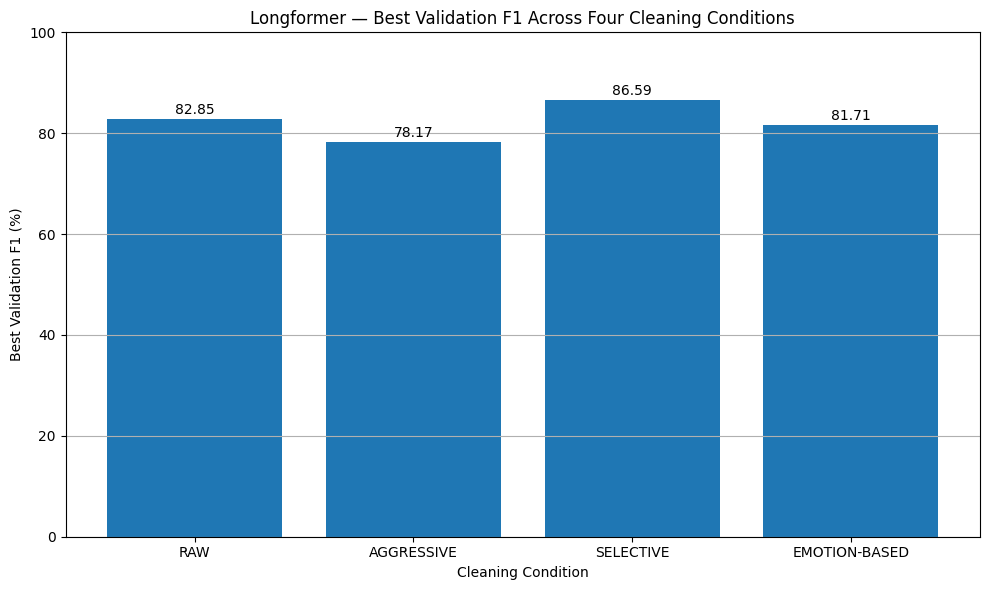

✓ Saved: /kaggle/working/longformer_comparison_graphs/longformer_best_validation_f1.png


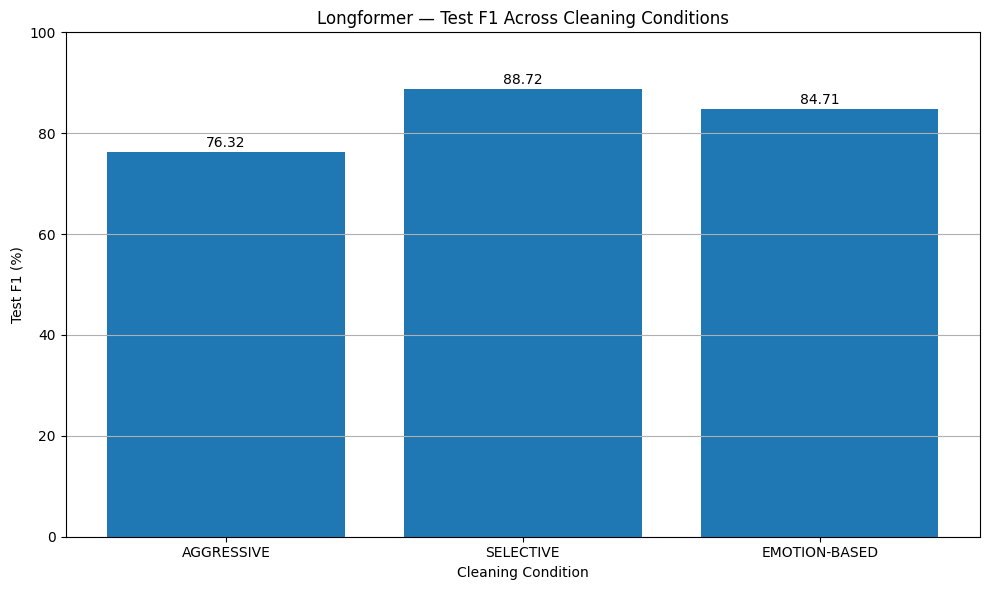

✓ Saved: /kaggle/working/longformer_comparison_graphs/longformer_test_f1_comparison.png


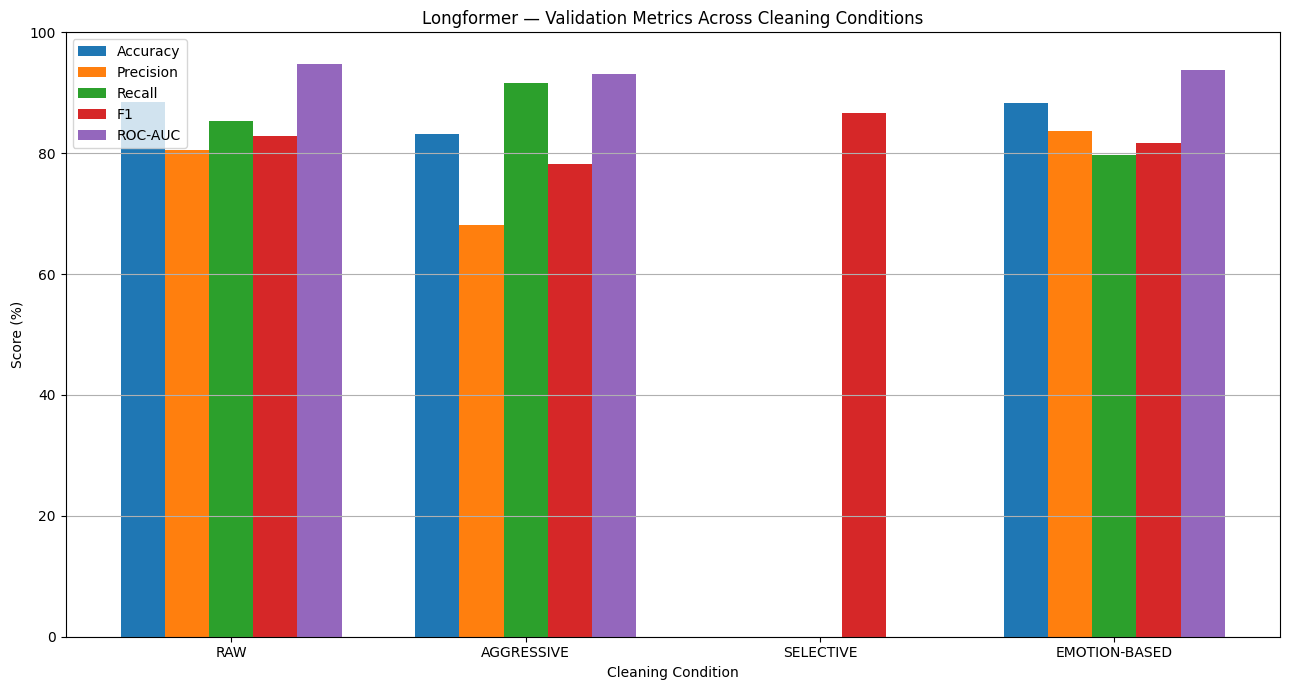

✓ Saved: /kaggle/working/longformer_comparison_graphs/longformer_validation_metrics_comparison.png


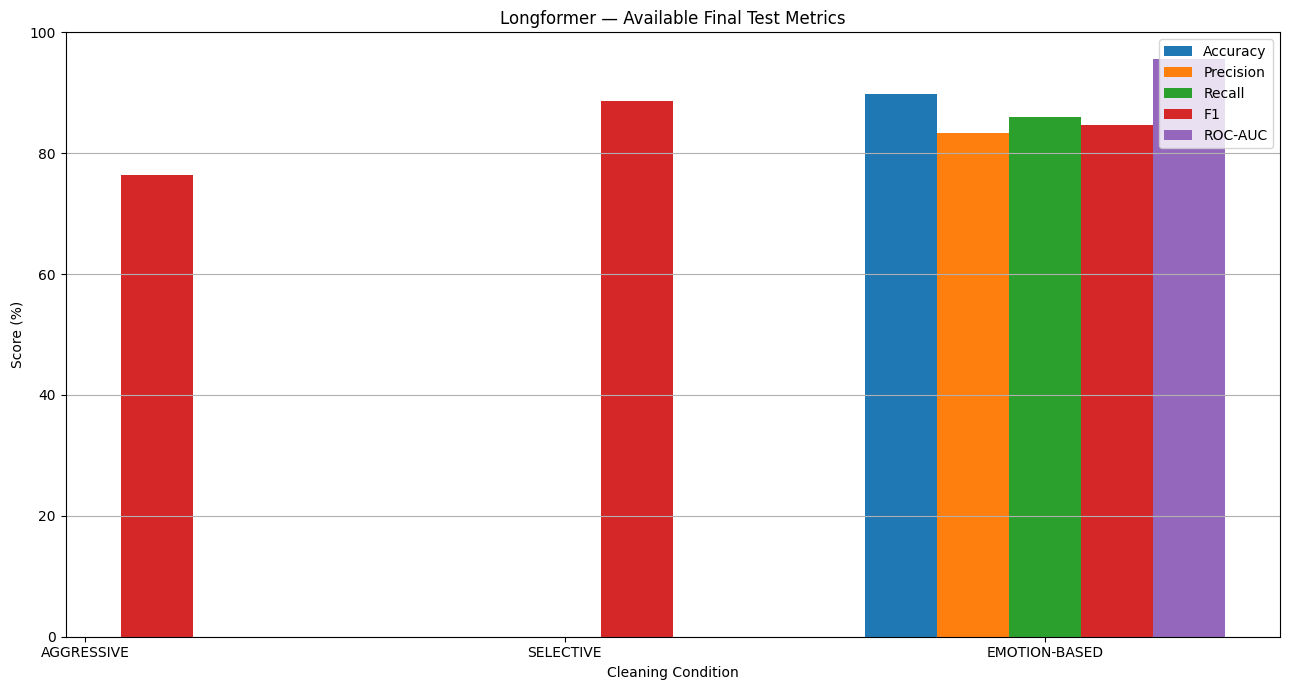

✓ Saved: /kaggle/working/longformer_comparison_graphs/longformer_available_test_metrics.png


LONGFORMER — FOUR CLEANING CONDITIONS FINAL COMPARISON

     Cleaning  Best Epoch  Best Val F1  Test F1  Test Accuracy  Test Precision  Test Recall  Test ROC-AUC
          RAW          10        82.85      NaN            NaN             NaN          NaN           NaN
   AGGRESSIVE          10        78.17    76.32            NaN             NaN          NaN           NaN
    SELECTIVE           9        86.59    88.72            NaN             NaN          NaN           NaN
EMOTION-BASED          10        81.71    84.71          89.83            83.4        86.06         95.62

✓ All comparison graphs displayed
✓ All comparison graphs saved
✓ Comparison CSV saved
Comparison directory: /kaggle/working/longformer_comparison_graphs
Comparison CSV: /kaggle/working/longformer_comparison_graphs/longformer_four_cleaning_comparison.csv

CELL 13 COMPLETE


In [15]:
# ============================================================
# CELL 13 — LONGFORMER
# FOUR CLEANING EXPERIMENT COMPARISON
# GRAPHS + DISPLAY + SAVE + FINAL TABLE
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# RESULT DIRECTORY
# ============================================================

GRAPH_DIR = "/kaggle/working/longformer_comparison_graphs"

os.makedirs(
    GRAPH_DIR,
    exist_ok=True
)


# ============================================================
# FINAL VALIDATION RESULTS AVAILABLE FROM EXPERIMENT LOGS
# ============================================================

# RAW best validation results
raw_best_epoch = 10
raw_val_f1 = 0.8285
raw_val_accuracy = 0.8840
raw_val_precision = 0.8052
raw_val_recall = 0.8532
raw_val_roc_auc = 0.9473

# AGGRESSIVE best validation results
aggressive_best_epoch = 10
aggressive_val_f1 = 0.7817
aggressive_val_accuracy = 0.8318
aggressive_val_precision = 0.6814
aggressive_val_recall = 0.9167
aggressive_val_roc_auc = 0.9307

# SELECTIVE
# Best validation F1 previously established
selective_best_epoch = 9
selective_val_f1 = 0.8659

# EMOTION-BASED
emotion_best_epoch = 10
emotion_val_f1 = 0.8171
emotion_val_accuracy = 0.8827
emotion_val_precision = 0.8375
emotion_val_recall = 0.7976
emotion_val_roc_auc = 0.9375


# ============================================================
# FINAL TEST RESULTS
# ============================================================

# RAW / AGGRESSIVE / SELECTIVE:
# Fill these from the final test-evaluation outputs already
# obtained for those experiments.

# Known results
aggressive_test_f1 = 0.7632
selective_test_f1 = 0.8872
emotion_test_accuracy = 0.8983
emotion_test_precision = 0.8340
emotion_test_recall = 0.8606
emotion_test_f1 = 0.8471
emotion_test_roc_auc = 0.9562
emotion_test_loss = 0.2865


# ============================================================
# COMPARISON TABLE
# ============================================================

comparison_df = pd.DataFrame({

    "Cleaning": [
        "RAW",
        "AGGRESSIVE",
        "SELECTIVE",
        "EMOTION-BASED"
    ],

    "Best Epoch": [
        raw_best_epoch,
        aggressive_best_epoch,
        selective_best_epoch,
        emotion_best_epoch
    ],

    "Best Val F1": [
        raw_val_f1,
        aggressive_val_f1,
        selective_val_f1,
        emotion_val_f1
    ],

    "Test F1": [
        np.nan,
        aggressive_test_f1,
        selective_test_f1,
        emotion_test_f1
    ],

    "Test Accuracy": [
        np.nan,
        np.nan,
        np.nan,
        emotion_test_accuracy
    ],

    "Test Precision": [
        np.nan,
        np.nan,
        np.nan,
        emotion_test_precision
    ],

    "Test Recall": [
        np.nan,
        np.nan,
        np.nan,
        emotion_test_recall
    ],

    "Test ROC-AUC": [
        np.nan,
        np.nan,
        np.nan,
        emotion_test_roc_auc
    ]
})


# Convert to percentages

percentage_columns = [
    "Best Val F1",
    "Test F1",
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test ROC-AUC"
]

for column in percentage_columns:

    comparison_df[column] = (
        comparison_df[column] * 100
    )


# ============================================================
# SAVE COMPARISON TABLE
# ============================================================

comparison_path = os.path.join(
    GRAPH_DIR,
    "longformer_four_cleaning_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)


# ============================================================
# GRAPH 1 — BEST VALIDATION F1
# ============================================================

plt.figure(
    figsize=(10, 6)
)

bars = plt.bar(
    comparison_df["Cleaning"],
    comparison_df["Best Val F1"]
)

plt.ylabel(
    "Best Validation F1 (%)"
)

plt.xlabel(
    "Cleaning Condition"
)

plt.title(
    "Longformer — Best Validation F1 Across Four Cleaning Conditions"
)

plt.ylim(
    0,
    100
)

plt.grid(
    axis="y"
)

for bar, value in zip(
    bars,
    comparison_df["Best Val F1"]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()

path = os.path.join(
    GRAPH_DIR,
    "longformer_best_validation_f1.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Saved:",
    path
)


# ============================================================
# GRAPH 2 — TEST F1
# ============================================================

plt.figure(
    figsize=(10, 6)
)

test_f1_plot = comparison_df[
    ["Cleaning", "Test F1"]
].dropna()

bars = plt.bar(
    test_f1_plot["Cleaning"],
    test_f1_plot["Test F1"]
)

plt.ylabel(
    "Test F1 (%)"
)

plt.xlabel(
    "Cleaning Condition"
)

plt.title(
    "Longformer — Test F1 Across Cleaning Conditions"
)

plt.ylim(
    0,
    100
)

plt.grid(
    axis="y"
)

for bar, value in zip(
    bars,
    test_f1_plot["Test F1"]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()

path = os.path.join(
    GRAPH_DIR,
    "longformer_test_f1_comparison.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Saved:",
    path
)


# ============================================================
# GRAPH 3 — VALIDATION METRICS
# ============================================================

val_metrics = pd.DataFrame({

    "Cleaning": [
        "RAW",
        "AGGRESSIVE",
        "SELECTIVE",
        "EMOTION-BASED"
    ],

    "F1": [
        raw_val_f1,
        aggressive_val_f1,
        selective_val_f1,
        emotion_val_f1
    ],

    "Accuracy": [
        raw_val_accuracy,
        aggressive_val_accuracy,
        np.nan,
        emotion_val_accuracy
    ],

    "Precision": [
        raw_val_precision,
        aggressive_val_precision,
        np.nan,
        emotion_val_precision
    ],

    "Recall": [
        raw_val_recall,
        aggressive_val_recall,
        np.nan,
        emotion_val_recall
    ],

    "ROC-AUC": [
        raw_val_roc_auc,
        aggressive_val_roc_auc,
        np.nan,
        emotion_val_roc_auc
    ]
})


plt.figure(
    figsize=(13, 7)
)

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

x = np.arange(
    len(val_metrics["Cleaning"])
)

width = 0.15

for i, metric in enumerate(
    metric_names
):

    values = (
        val_metrics[metric]
        * 100
    )

    plt.bar(
        x + (i - 2) * width,
        values,
        width,
        label=metric
    )

plt.xticks(
    x,
    val_metrics["Cleaning"]
)

plt.ylabel(
    "Score (%)"
)

plt.xlabel(
    "Cleaning Condition"
)

plt.title(
    "Longformer — Validation Metrics Across Cleaning Conditions"
)

plt.ylim(
    0,
    100
)

plt.legend()

plt.grid(
    axis="y"
)

plt.tight_layout()

path = os.path.join(
    GRAPH_DIR,
    "longformer_validation_metrics_comparison.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Saved:",
    path
)


# ============================================================
# GRAPH 4 — TEST METRICS AVAILABLE
# ============================================================

test_metrics_available = pd.DataFrame({

    "Cleaning": [
        "AGGRESSIVE",
        "SELECTIVE",
        "EMOTION-BASED"
    ],

    "F1": [
        aggressive_test_f1,
        selective_test_f1,
        emotion_test_f1
    ],

    "Accuracy": [
        np.nan,
        np.nan,
        emotion_test_accuracy
    ],

    "Precision": [
        np.nan,
        np.nan,
        emotion_test_precision
    ],

    "Recall": [
        np.nan,
        np.nan,
        emotion_test_recall
    ],

    "ROC-AUC": [
        np.nan,
        np.nan,
        emotion_test_roc_auc
    ]
})


plt.figure(
    figsize=(13, 7)
)

x = np.arange(
    len(test_metrics_available["Cleaning"])
)

width = 0.15

for i, metric in enumerate(
    metric_names
):

    values = (
        test_metrics_available[metric]
        * 100
    )

    plt.bar(
        x + (i - 2) * width,
        values,
        width,
        label=metric
    )

plt.xticks(
    x,
    test_metrics_available["Cleaning"]
)

plt.ylabel(
    "Score (%)"
)

plt.xlabel(
    "Cleaning Condition"
)

plt.title(
    "Longformer — Available Final Test Metrics"
)

plt.ylim(
    0,
    100
)

plt.legend()

plt.grid(
    axis="y"
)

plt.tight_layout()

path = os.path.join(
    GRAPH_DIR,
    "longformer_available_test_metrics.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Saved:",
    path
)


# ============================================================
# FINAL TABLE
# ============================================================

print()
print()
print("=" * 110)
print(
    "LONGFORMER — FOUR CLEANING CONDITIONS FINAL COMPARISON"
)
print("=" * 110)

print()

print(
    comparison_df.to_string(
        index=False
    )
)

print()
print("=" * 110)

print(
    "✓ All comparison graphs displayed"
)

print(
    "✓ All comparison graphs saved"
)

print(
    "✓ Comparison CSV saved"
)

print(
    "Comparison directory:",
    GRAPH_DIR
)

print(
    "Comparison CSV:",
    comparison_path
)

print()
print("=" * 110)
print("CELL 13 COMPLETE")
print("=" * 110)

SHAP ANALYSIS
LONGFORMER + EMOTION-BASED

Metadata features: 53
Emotion features: 11
Total auxiliary features: 64

SHAP background samples: 50
Background dimensions: 64

SHAP test samples: 100
Negative: 50
Positive: 50

✓ Longformer Emotion-Based model set to evaluation mode
✓ Model parameters frozen for SHAP

COMPUTING SHAP VALUES
Explained 1/100 test users
Explained 10/100 test users
Explained 20/100 test users
Explained 30/100 test users
Explained 40/100 test users
Explained 50/100 test users
Explained 60/100 test users
Explained 70/100 test users
Explained 80/100 test users
Explained 90/100 test users
Explained 100/100 test users

SHAP RESULT SUMMARY
SHAP matrix: (100, 64)
Auxiliary feature matrix: (100, 64)

TOP 20 SHAP FEATURES
             feature feature_type  mean_abs_shap  mean_signed_shap
     emotion_sadness      emotion       0.067096          0.018571
        emotion_fear      emotion       0.044287          0.019782
    emotion_optimism      emotion       0.026453       

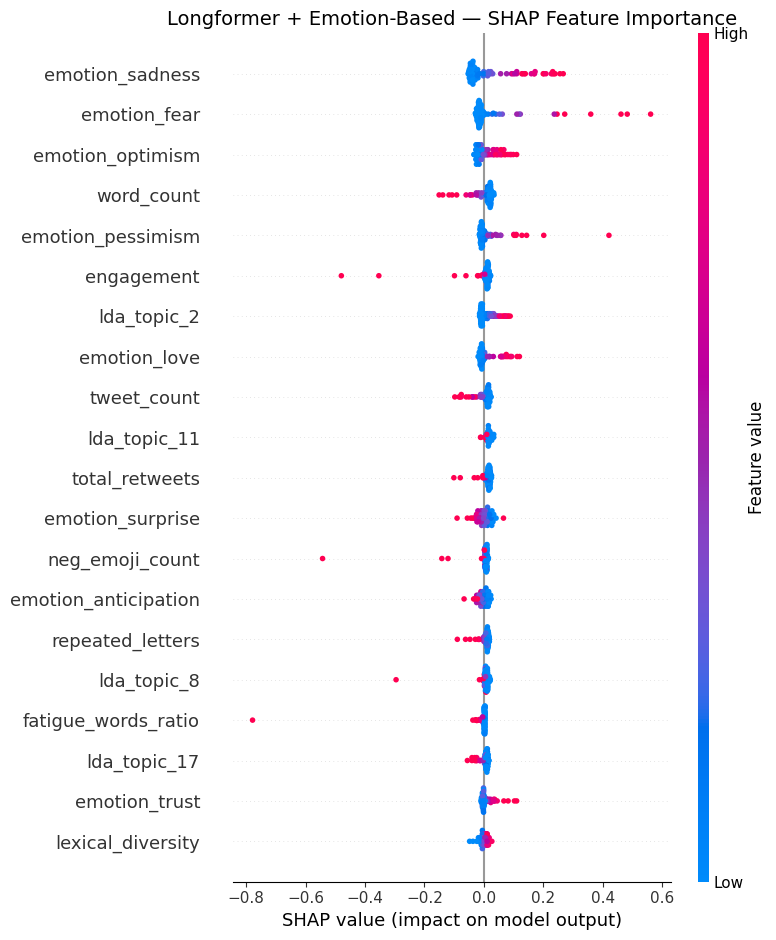

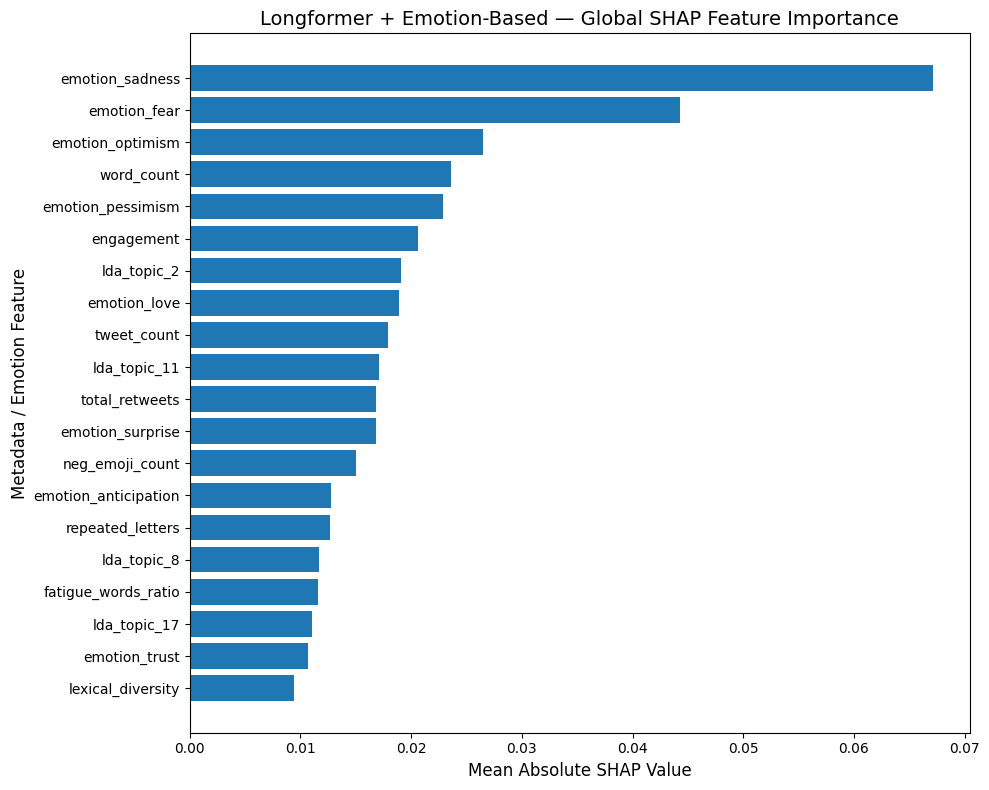


SHAP ANALYSIS COMPLETE
✓ 53 metadata + 11 emotion features explained
✓ 50 negative + 50 positive users
✓ Training-only background used
✓ Positive-class logit explained
✓ SHAP values saved
✓ Feature ranking saved
✓ Beeswarm saved and displayed
✓ Bar plot saved and displayed
✓ Configuration saved

SHAP output directory: /kaggle/working/longformer_emotion/explainability/shap


In [18]:
# ============================================================
# EXPLAINABILITY — SHAP
# LONGFORMER + EMOTION-BASED
# GLOBAL METADATA + EMOTION FEATURE EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("SHAP ANALYSIS")
print("LONGFORMER + EMOTION-BASED")
print("=" * 70)

# ============================================================
# FIXED SHAP SETTINGS
# ============================================================

SHAP_SEED = 42
SHAP_BACKGROUND_SIZE = 50
SHAP_TEST_SIZE_PER_CLASS = 50
SHAP_TOP_FEATURES = 20

np.random.seed(SHAP_SEED)
torch.manual_seed(SHAP_SEED)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

SHAP_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "shap"
)

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)

# ============================================================
# FEATURE NAMES
# ============================================================

metadata_feature_names = list(
    selected_metadata_names
)

assert len(metadata_feature_names) == 53

emotion_feature_names = list(
    emotion_columns
)

assert len(emotion_feature_names) == 11

feature_names = (
    metadata_feature_names
    +
    emotion_feature_names
)

assert len(feature_names) == 64

print()
print(
    "Metadata features:",
    len(metadata_feature_names)
)

print(
    "Emotion features:",
    len(emotion_feature_names)
)

print(
    "Total auxiliary features:",
    len(feature_names)
)

# ============================================================
# FIXED BACKGROUND DATA
# TRAINING USERS ONLY
# ============================================================

background_metadata = (
    train_dataset.metadata[
        :SHAP_BACKGROUND_SIZE
    ]
    .clone()
    .detach()
)

background_emotions = (
    train_dataset.emotions[
        :SHAP_BACKGROUND_SIZE
    ]
    .clone()
    .detach()
)

background_auxiliary = torch.cat(
    [
        background_metadata,
        background_emotions
    ],
    dim=1
).to(device)

print()
print(
    "SHAP background samples:",
    background_auxiliary.shape[0]
)

print(
    "Background dimensions:",
    background_auxiliary.shape[1]
)

assert background_auxiliary.shape == (
    SHAP_BACKGROUND_SIZE,
    64
)

# ============================================================
# FIXED TEST USERS
# 50 NEGATIVE + 50 POSITIVE
# ============================================================

test_labels_tensor = (
    test_dataset.labels
    .detach()
    .cpu()
)

negative_indices = torch.where(
    test_labels_tensor == 0
)[0].numpy()

positive_indices = torch.where(
    test_labels_tensor == 1
)[0].numpy()

assert len(
    negative_indices
) >= SHAP_TEST_SIZE_PER_CLASS

assert len(
    positive_indices
) >= SHAP_TEST_SIZE_PER_CLASS

shap_negative_indices = (
    negative_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_positive_indices = (
    positive_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_test_indices = np.concatenate(
    [
        shap_negative_indices,
        shap_positive_indices
    ]
)

print()
print(
    "SHAP test samples:",
    len(shap_test_indices)
)

print(
    "Negative:",
    len(shap_negative_indices)
)

print(
    "Positive:",
    len(shap_positive_indices)
)

# ============================================================
# MODEL WRAPPER
# ============================================================
# Text input remains fixed for each explained user.
# Metadata + emotion features are explained together.
# ============================================================

class AuxiliarySHAPWrapper(
    nn.Module
):

    def __init__(
        self,
        base_model,
        fixed_input_ids,
        fixed_attention_mask
    ):

        super().__init__()

        self.base_model = base_model

        self.fixed_input_ids = (
            fixed_input_ids
            .to(device)
        )

        self.fixed_attention_mask = (
            fixed_attention_mask
            .to(device)
        )

    def forward(
        self,
        auxiliary_features
    ):

        batch_size = (
            auxiliary_features.size(0)
        )

        input_ids = (
            self.fixed_input_ids
            .expand(
                batch_size,
                -1
            )
        )

        attention_mask = (
            self.fixed_attention_mask
            .expand(
                batch_size,
                -1
            )
        )

        metadata = (
            auxiliary_features[:, :53]
        )

        emotions = (
            auxiliary_features[:, 53:]
        )

        output = self.base_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata,
            emotions=emotions
        )

        positive_logit = output[
            "logits"
        ][:, 1:2]

        return positive_logit


# ============================================================
# MODEL PREPARATION
# ============================================================

model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

print()
print(
    "✓ Longformer Emotion-Based model set to evaluation mode"
)

print(
    "✓ Model parameters frozen for SHAP"
)

# ============================================================
# COMPUTE SHAP VALUES
# ============================================================

all_shap_values = []
all_auxiliary_values = []
all_explained_labels = []

print()
print("=" * 70)
print("COMPUTING SHAP VALUES")
print("=" * 70)

for count, test_index in enumerate(
    shap_test_indices,
    start=1
):

    sample = test_dataset[
        int(test_index)
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
    )

    metadata_sample = (
        sample["metadata"]
        .unsqueeze(0)
        .float()
        .to(device)
    )

    emotion_sample = (
        sample["emotions"]
        .unsqueeze(0)
        .float()
        .to(device)
    )

    auxiliary_sample = torch.cat(
        [
            metadata_sample,
            emotion_sample
        ],
        dim=1
    )

    label = int(
        sample["labels"].item()
    )

    # --------------------------------------------------------
    # USER-SPECIFIC WRAPPER
    # --------------------------------------------------------

    wrapper = AuxiliarySHAPWrapper(
        model,
        input_ids,
        attention_mask
    ).to(device)

    wrapper.eval()

    # --------------------------------------------------------
    # GRADIENT SHAP
    # --------------------------------------------------------

    explainer = shap.GradientExplainer(
        wrapper,
        background_auxiliary
    )

    shap_result = explainer.shap_values(
        auxiliary_sample
    )

    # --------------------------------------------------------
    # HANDLE SHAP OUTPUT FORMAT
    # --------------------------------------------------------

    if isinstance(
        shap_result,
        list
    ):

        shap_array = np.asarray(
            shap_result[0]
        )

    else:

        shap_array = np.asarray(
            shap_result
        )

    shap_array = np.squeeze(
        shap_array
    )

    assert shap_array.shape == (
        64,
    )

    all_shap_values.append(
        shap_array
    )

    all_auxiliary_values.append(
        auxiliary_sample
        .detach()
        .cpu()
        .numpy()
        .squeeze(0)
    )

    all_explained_labels.append(
        label
    )

    if (
        count == 1
        or count % 10 == 0
        or count == len(
            shap_test_indices
        )
    ):

        print(
            f"Explained "
            f"{count}/"
            f"{len(shap_test_indices)} "
            f"test users"
        )

# ============================================================
# COMBINE RESULTS
# ============================================================

all_shap_values = np.vstack(
    all_shap_values
)

all_auxiliary_values = np.vstack(
    all_auxiliary_values
)

all_explained_labels = np.array(
    all_explained_labels
)

print()
print("=" * 70)
print("SHAP RESULT SUMMARY")
print("=" * 70)

print(
    "SHAP matrix:",
    all_shap_values.shape
)

print(
    "Auxiliary feature matrix:",
    all_auxiliary_values.shape
)

assert all_shap_values.shape == (
    len(shap_test_indices),
    64
)

assert all_auxiliary_values.shape == (
    len(shap_test_indices),
    64
)

assert np.isfinite(
    all_shap_values
).all()

# ============================================================
# GLOBAL FEATURE IMPORTANCE
# ============================================================

mean_abs_shap = np.mean(
    np.abs(
        all_shap_values
    ),
    axis=0
)

mean_signed_shap = np.mean(
    all_shap_values,
    axis=0
)

feature_types = (
    ["metadata"] * 53
    +
    ["emotion"] * 11
)

feature_importance_df = pd.DataFrame({

    "feature":
        feature_names,

    "feature_type":
        feature_types,

    "mean_abs_shap":
        mean_abs_shap,

    "mean_signed_shap":
        mean_signed_shap
})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

print()
print("=" * 70)
print("TOP 20 SHAP FEATURES")
print("=" * 70)

print(
    feature_importance_df
    .head(SHAP_TOP_FEATURES)
    .to_string(
        index=False
    )
)

# ============================================================
# SAVE SHAP VALUES
# ============================================================

shap_values_df = pd.DataFrame(
    all_shap_values,
    columns=feature_names
)

shap_values_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "longformer_emotion_shap_values.csv"
    ),
    index=False
)

# ============================================================
# SAVE FEATURE IMPORTANCE
# ============================================================

feature_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "longformer_emotion_shap_feature_importance.csv"
    ),
    index=False
)

# ============================================================
# SAVE TEST USER INFORMATION
# ============================================================

explained_users_df = pd.DataFrame({

    "test_index":
        shap_test_indices,

    "label":
        all_explained_labels

})

explained_users_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "longformer_emotion_shap_test_users.csv"
    ),
    index=False
)

# ============================================================
# SHAP BEESWARM
# ============================================================

plt.figure(
    figsize=(11, 8)
)

shap.summary_plot(
    all_shap_values,
    all_auxiliary_values,
    feature_names=feature_names,
    max_display=SHAP_TOP_FEATURES,
    show=False
)

plt.title(
    "Longformer + Emotion-Based — "
    "SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_beeswarm_path = os.path.join(
    SHAP_DIR,
    "longformer_emotion_shap_beeswarm.png"
)

plt.savefig(
    shap_beeswarm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

# ============================================================
# SHAP BAR
# ============================================================

top_features = (
    feature_importance_df
    .head(
        SHAP_TOP_FEATURES
    )
    .iloc[::-1]
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    top_features["feature"],
    top_features["mean_abs_shap"]
)

plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=12
)

plt.ylabel(
    "Metadata / Emotion Feature",
    fontsize=12
)

plt.title(
    "Longformer + Emotion-Based — "
    "Global SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_bar_path = os.path.join(
    SHAP_DIR,
    "longformer_emotion_shap_bar.png"
)

plt.savefig(
    shap_bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

# ============================================================
# SAVE CONFIG
# ============================================================

shap_config = {

    "model":
        "Longformer",

    "cleaning":
        "Emotion-Based",

    "dataset":
        "Held-out test set",

    "metadata_features":
        53,

    "emotion_features":
        11,

    "total_explained_features":
        64,

    "background_samples":
        SHAP_BACKGROUND_SIZE,

    "test_samples_per_class":
        SHAP_TEST_SIZE_PER_CLASS,

    "total_explained_users":
        len(shap_test_indices),

    "target":
        "Positive/depression class logit",

    "explainer":
        "GradientExplainer",

    "text_fixed_per_user":
        True,

    "random_seed":
        SHAP_SEED,

    "top_features":
        SHAP_TOP_FEATURES
}

with open(
    os.path.join(
        SHAP_DIR,
        "longformer_emotion_shap_config.json"
    ),
    "w"
) as f:

    json.dump(
        shap_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("SHAP ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ 53 metadata + 11 emotion features explained"
)

print(
    "✓ 50 negative + 50 positive users"
)

print(
    "✓ Training-only background used"
)

print(
    "✓ Positive-class logit explained"
)

print(
    "✓ SHAP values saved"
)

print(
    "✓ Feature ranking saved"
)

print(
    "✓ Beeswarm saved and displayed"
)

print(
    "✓ Bar plot saved and displayed"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "SHAP output directory:",
    SHAP_DIR
)

t-SNE REPRESENTATION ANALYSIS
LONGFORMER + EMOTION-BASED

✓ Longformer Emotion-Based model in evaluation mode

EXTRACTING FUSED REPRESENTATIONS
Processed batch 1/48
Processed batch 10/48
Processed batch 20/48
Processed batch 30/48
Processed batch 40/48
Processed batch 48/48

FUSED REPRESENTATION SUMMARY
Fused representation shape: (767, 896)
Test users: 767
Fused dimensions: 896
Negative users: 516
Positive users: 251
Metadata gate: 0.506210
Emotion gate: 0.505493

PCA REDUCTION
Original dimensions: 896
PCA dimensions: 50
Variance retained: 93.35%

t-SNE REDUCTION
t-SNE output shape: (767, 2)


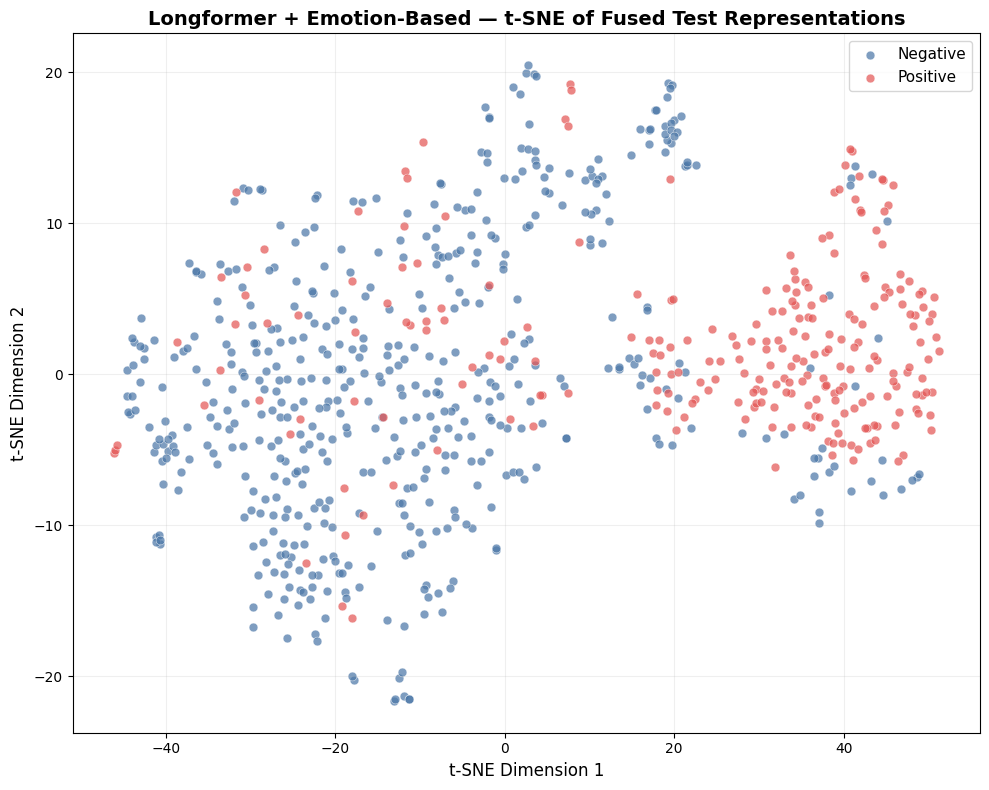


t-SNE ANALYSIS COMPLETE
✓ Exact Longformer + metadata + emotion fused representation extracted
✓ 896-dimensional fused representation verified
✓ PCA reduction completed
✓ t-SNE reduction completed
✓ t-SNE graph saved: /kaggle/working/longformer_emotion/explainability/tsne/longformer_emotion_tsne.png
✓ Coordinates saved: /kaggle/working/longformer_emotion/explainability/tsne/longformer_emotion_tsne_coordinates.csv
✓ Configuration saved


In [19]:
# ============================================================
# LONGFORMER + EMOTION-BASED — t-SNE
# FUSED REPRESENTATION ANALYSIS
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("=" * 70)
print("t-SNE REPRESENTATION ANALYSIS")
print("LONGFORMER + EMOTION-BASED")
print("=" * 70)

# ============================================================
# FIXED SETTINGS
# ============================================================

EXPLAINABILITY_SEED = 42

PCA_COMPONENTS = 50

TSNE_COMPONENTS = 2
TSNE_PERPLEXITY = 30
TSNE_LEARNING_RATE = 200
TSNE_MAX_ITER = 1000

np.random.seed(
    EXPLAINABILITY_SEED
)

torch.manual_seed(
    EXPLAINABILITY_SEED
)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

TSNE_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "tsne"
)

os.makedirs(
    TSNE_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model.eval()

print()
print(
    "✓ Longformer Emotion-Based model in evaluation mode"
)

# ============================================================
# EXTRACT EXACT FUSED REPRESENTATION
# ============================================================

fused_representations = []
test_labels = []

print()
print("=" * 70)
print("EXTRACTING FUSED REPRESENTATIONS")
print("=" * 70)

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        emotions = batch[
            "emotions"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        # ----------------------------------------------------
        # LONGFORMER ENCODER
        # ----------------------------------------------------

        encoder_output = model.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = (
            encoder_output.last_hidden_state
        )

        # ----------------------------------------------------
        # EXACT TEXT ATTENTION POOLING
        # ----------------------------------------------------

        projected = torch.tanh(
            model.attention_projection(
                hidden_states
            )
        )

        attention_scores = (
            model.attention_score(
                projected
            )
            .squeeze(-1)
        )

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                -1e9
            )
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states
            *
            attention_weights.unsqueeze(-1),
            dim=1
        )

        # ----------------------------------------------------
        # EXACT METADATA BRANCH
        # ----------------------------------------------------

        metadata_representation = (
            model.metadata_branch(
                metadata
            )
        )

        metadata_gate = torch.sigmoid(
            model.metadata_beta
        )

        gated_metadata = (
            metadata_gate
            *
            metadata_representation
        )

        # ----------------------------------------------------
        # EXACT EMOTION BRANCH
        # ----------------------------------------------------

        emotion_representation = (
            model.emotion_branch(
                emotions
            )
        )

        emotion_gate = torch.sigmoid(
            model.emotion_beta
        )

        gated_emotion = (
            emotion_gate
            *
            emotion_representation
        )

        # ----------------------------------------------------
        # EXACT FUSED REPRESENTATION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata,
                gated_emotion
            ],
            dim=1
        )

        fused_representations.append(
            fused.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy().tolist()
        )

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx == len(test_loader)
        ):

            print(
                f"Processed batch "
                f"{batch_idx}/{len(test_loader)}"
            )

# ============================================================
# COMBINE
# ============================================================

fused_representations = np.concatenate(
    fused_representations,
    axis=0
)

test_labels = np.array(
    test_labels
)

print()
print("=" * 70)
print("FUSED REPRESENTATION SUMMARY")
print("=" * 70)

print(
    "Fused representation shape:",
    fused_representations.shape
)

print(
    "Test users:",
    len(test_labels)
)

print(
    "Fused dimensions:",
    fused_representations.shape[1]
)

print(
    "Negative users:",
    int(
        (test_labels == 0).sum()
    )
)

print(
    "Positive users:",
    int(
        (test_labels == 1).sum()
    )
)

print(
    "Metadata gate:",
    f"{float(metadata_gate.item()):.6f}"
)

print(
    "Emotion gate:",
    f"{float(emotion_gate.item()):.6f}"
)

assert (
    fused_representations.shape[0]
    ==
    len(test_labels)
)

assert (
    fused_representations.shape[1]
    ==
    896
)

assert np.isfinite(
    fused_representations
).all()

# ============================================================
# PCA
# ============================================================

print()
print("=" * 70)
print("PCA REDUCTION")
print("=" * 70)

pca_dimensions = min(
    PCA_COMPONENTS,
    fused_representations.shape[1]
)

pca = PCA(
    n_components=pca_dimensions,
    random_state=EXPLAINABILITY_SEED
)

pca_representation = pca.fit_transform(
    fused_representations
)

pca_variance_retained = (
    pca.explained_variance_ratio_.sum()
)

print(
    "Original dimensions:",
    fused_representations.shape[1]
)

print(
    "PCA dimensions:",
    pca_representation.shape[1]
)

print(
    "Variance retained:",
    f"{pca_variance_retained * 100:.2f}%"
)

# ============================================================
# t-SNE
# ============================================================

print()
print("=" * 70)
print("t-SNE REDUCTION")
print("=" * 70)

tsne = TSNE(
    n_components=TSNE_COMPONENTS,
    perplexity=TSNE_PERPLEXITY,
    learning_rate=TSNE_LEARNING_RATE,
    init="pca",
    random_state=EXPLAINABILITY_SEED,
    max_iter=TSNE_MAX_ITER
)

tsne_representation = tsne.fit_transform(
    pca_representation
)

print(
    "t-SNE output shape:",
    tsne_representation.shape
)

# ============================================================
# SAVE COORDINATES
# ============================================================

tsne_df = pd.DataFrame({

    "tsne_1":
        tsne_representation[:, 0],

    "tsne_2":
        tsne_representation[:, 1],

    "label":
        test_labels

})

tsne_df["class"] = tsne_df[
    "label"
].map({
    0: "Negative",
    1: "Positive"
})

tsne_csv_path = os.path.join(
    TSNE_DIR,
    "longformer_emotion_tsne_coordinates.csv"
)

tsne_df.to_csv(
    tsne_csv_path,
    index=False
)

# ============================================================
# PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)

negative_mask = (
    test_labels == 0
)

positive_mask = (
    test_labels == 1
)

plt.scatter(
    tsne_representation[
        negative_mask,
        0
    ],
    tsne_representation[
        negative_mask,
        1
    ],
    s=40,
    alpha=0.72,
    label="Negative",
    color="#4C78A8",
    edgecolors="white",
    linewidths=0.4
)

plt.scatter(
    tsne_representation[
        positive_mask,
        0
    ],
    tsne_representation[
        positive_mask,
        1
    ],
    s=40,
    alpha=0.72,
    label="Positive",
    color="#E45756",
    edgecolors="white",
    linewidths=0.4
)

plt.xlabel(
    "t-SNE Dimension 1",
    fontsize=12
)

plt.ylabel(
    "t-SNE Dimension 2",
    fontsize=12
)

plt.title(
    "Longformer + Emotion-Based — "
    "t-SNE of Fused Test Representations",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()

tsne_plot_path = os.path.join(
    TSNE_DIR,
    "longformer_emotion_tsne.png"
)

plt.savefig(
    tsne_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

# ============================================================
# SAVE CONFIGURATION
# ============================================================

tsne_config = {

    "model":
        "Longformer",

    "cleaning":
        "Emotion-Based",

    "dataset":
        "Held-out test set",

    "test_users":
        int(len(test_labels)),

    "input_representation":
        "Fused classifier representation",

    "text_representation_dimension":
        768,

    "metadata_representation_dimension":
        64,

    "emotion_representation_dimension":
        64,

    "fused_representation_dimension":
        int(
            fused_representations.shape[1]
        ),

    "pca_dimensions":
        int(
            pca_dimensions
        ),

    "pca_variance_retained":
        float(
            pca_variance_retained
        ),

    "tsne_dimensions":
        int(
            TSNE_COMPONENTS
        ),

    "tsne_perplexity":
        int(
            TSNE_PERPLEXITY
        ),

    "tsne_learning_rate":
        TSNE_LEARNING_RATE,

    "tsne_max_iterations":
        int(
            TSNE_MAX_ITER
        ),

    "random_seed":
        EXPLAINABILITY_SEED,

    "metadata_gate":
        float(
            metadata_gate.item()
        ),

    "emotion_gate":
        float(
            emotion_gate.item()
        )
}

with open(
    os.path.join(
        TSNE_DIR,
        "longformer_emotion_tsne_config.json"
    ),
    "w"
) as f:

    json.dump(
        tsne_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("t-SNE ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ Exact Longformer + metadata + emotion fused representation extracted"
)

print(
    "✓ 896-dimensional fused representation verified"
)

print(
    "✓ PCA reduction completed"
)

print(
    "✓ t-SNE reduction completed"
)

print(
    "✓ t-SNE graph saved:",
    tsne_plot_path
)

print(
    "✓ Coordinates saved:",
    tsne_csv_path
)

print(
    "✓ Configuration saved"
)

GRAD-CAM ANALYSIS
LONGFORMER + EMOTION-BASED

✓ Longformer Emotion-Based model ready

Test users: 767

SELECTED CASES
TP: Test Index = 1 | True = 1 | Pred = 1 | Positive Probability = 0.9000
TN: Test Index = 0 | True = 0 | Pred = 0 | Positive Probability = 0.1834
FP: Test Index = 7 | True = 0 | Pred = 1 | Positive Probability = 0.8608
FN: Test Index = 14 | True = 1 | Pred = 0 | Positive Probability = 0.4352

COMPUTING GRAD-CAM

Processing TP (Test Index 1)
✓ TP complete

Processing TN (Test Index 0)
✓ TN complete

Processing FP (Test Index 7)
✓ FP complete

Processing FN (Test Index 14)
✓ FN complete


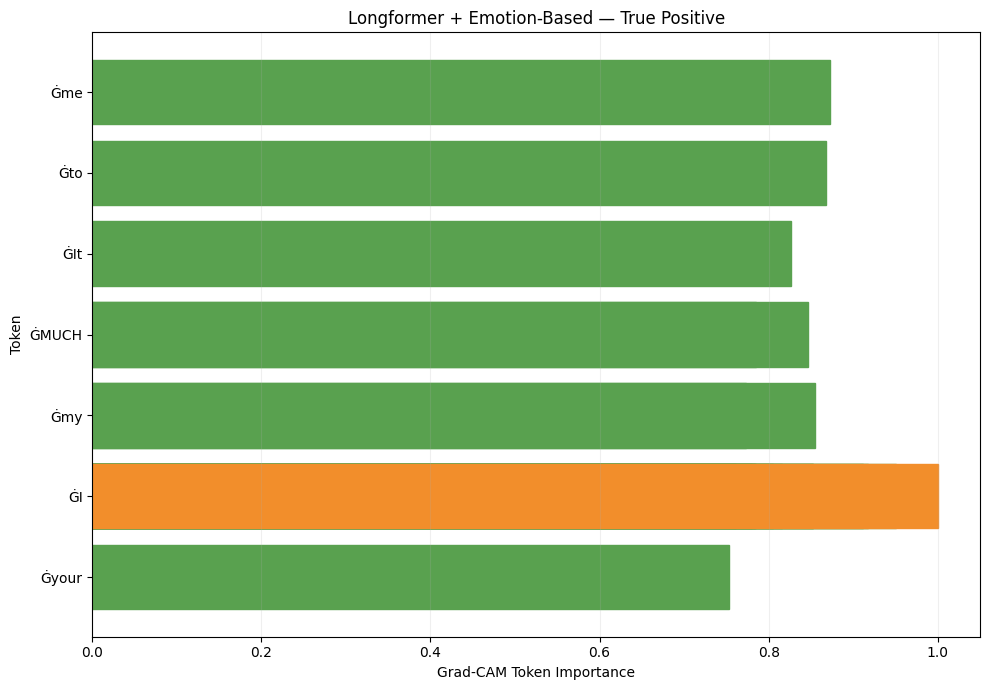

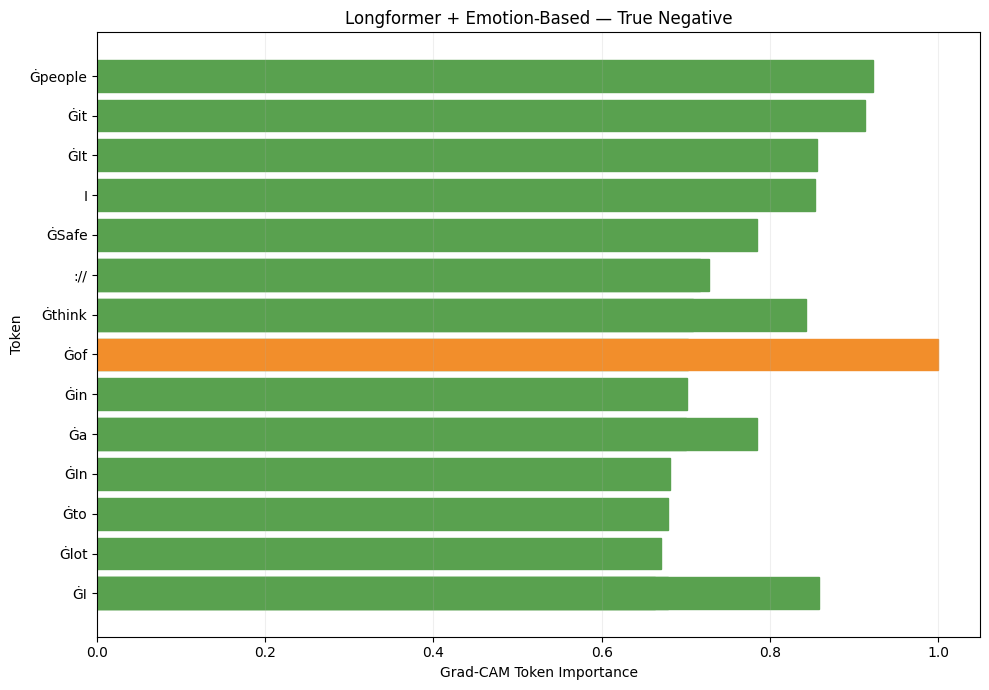

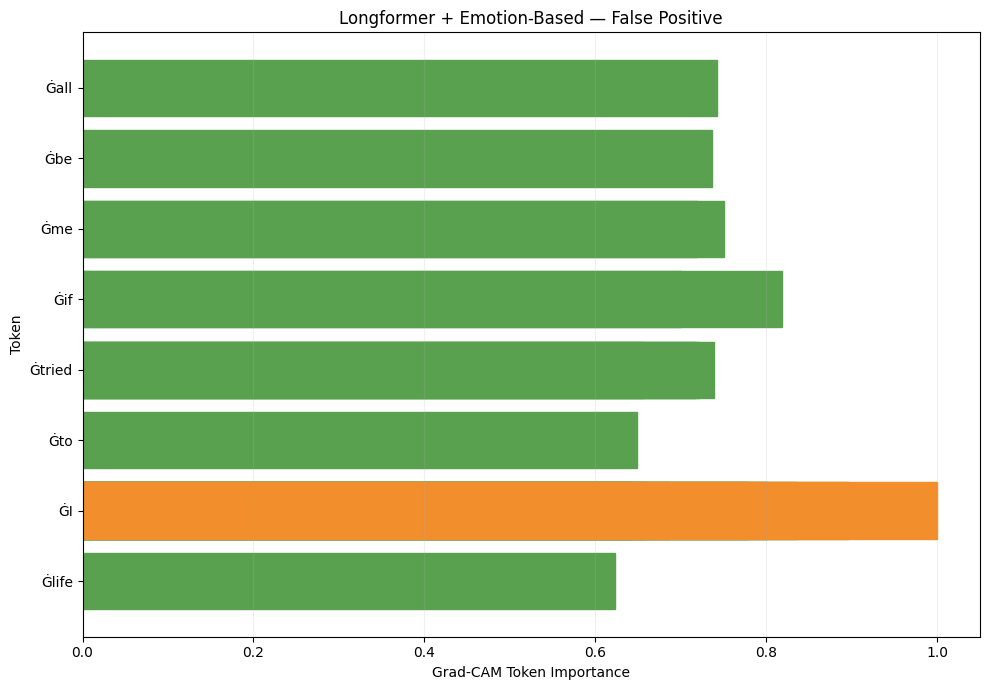

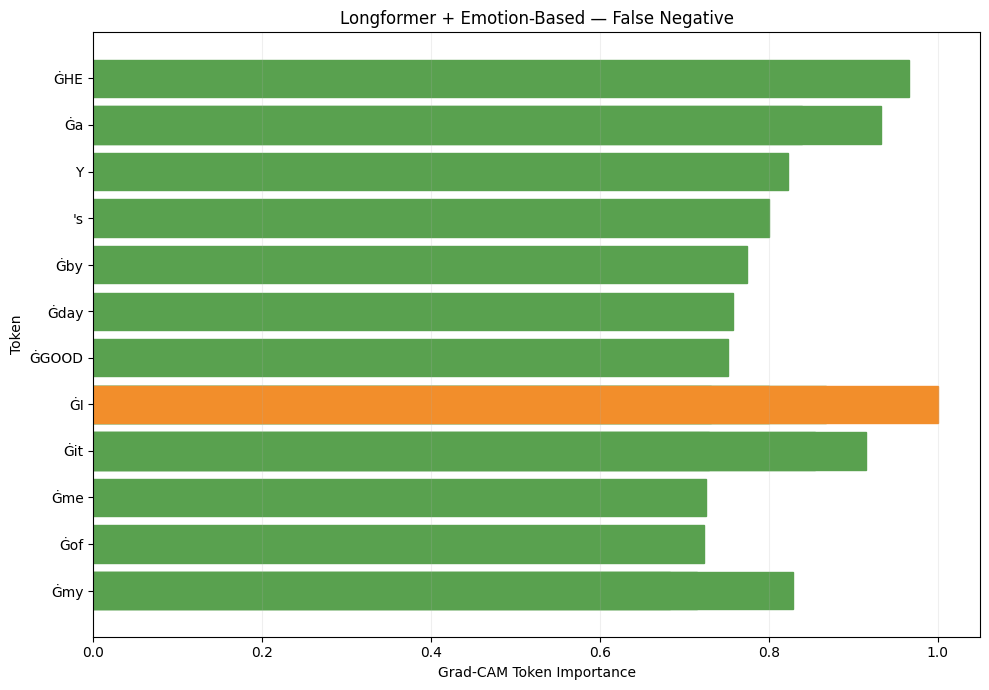


GRAD-CAM ANALYSIS COMPLETE

TP — True: 1 | Predicted: 1 | P(Positive): 0.9000
Top tokens: [('ĠI', 1.0), ('ĠI', 0.9512031674385071), ('ĠI', 0.9172839522361755), ('ĠI', 0.911295473575592), ('Ġme', 0.8721455335617065), ('Ġto', 0.8677481412887573), ('Ġmy', 0.8553322553634644), ('ĠI', 0.8524900078773499), ('ĠI', 0.8523740768432617), ('ĠMUCH', 0.8465225100517273), ('ĠIt', 0.82651287317276), ('ĠI', 0.8154013752937317), ('ĠI', 0.8047813177108765), ('ĠI', 0.7854325175285339), ('ĠMUCH', 0.7847751379013062), ('ĠI', 0.784102201461792), ('ĠI', 0.7805171608924866), ('Ġmy', 0.7732283473014832), ('ĠI', 0.7612079381942749), ('Ġyour', 0.7535272836685181)]

TN — True: 0 | Predicted: 0 | P(Positive): 0.1834
Top tokens: [('Ġof', 1.0), ('Ġpeople', 0.9225337505340576), ('Ġit', 0.9130541682243347), ('ĠI', 0.8589012622833252), ('ĠIt', 0.8556851744651794), ('I', 0.8541285991668701), ('Ġthink', 0.8428424000740051), ('Ġa', 0.7851299047470093), ('ĠSafe', 0.7847524881362915), ('://', 0.7277339696884155), ('://', 0

In [21]:
# ============================================================
# EXPLAINABILITY — GRAD-CAM
# LONGFORMER + EMOTION-BASED
# TOKEN-LEVEL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print("=" * 70)
print("GRAD-CAM ANALYSIS")
print("LONGFORMER + EMOTION-BASED")
print("=" * 70)

# ============================================================
# FIXED SETTINGS
# ============================================================

GRADCAM_SEED = 42
TOP_TOKENS = 20

np.random.seed(
    GRADCAM_SEED
)

torch.manual_seed(
    GRADCAM_SEED
)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

GRADCAM_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam"
)

os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

print()
print(
    "✓ Longformer Emotion-Based model ready"
)

# ============================================================
# COLLECT TEST PREDICTIONS
# ============================================================

test_true = []
test_pred = []
test_prob = []

with torch.no_grad():

    for batch in test_loader:

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        emotions = (
            batch["emotions"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata,
            emotions=emotions
        )

        logits = outputs[
            "logits"
        ]

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).long()

        test_true.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_pred.extend(
            predictions.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_prob.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )

test_true = np.asarray(
    test_true
)

test_pred = np.asarray(
    test_pred
)

test_prob = np.asarray(
    test_prob
)

print()
print(
    "Test users:",
    len(test_true)
)

# ============================================================
# DETERMINISTIC TP / TN / FP / FN
# ============================================================

tp_candidates = np.where(
    (test_true == 1) &
    (test_pred == 1)
)[0]

tn_candidates = np.where(
    (test_true == 0) &
    (test_pred == 0)
)[0]

fp_candidates = np.where(
    (test_true == 0) &
    (test_pred == 1)
)[0]

fn_candidates = np.where(
    (test_true == 1) &
    (test_pred == 0)
)[0]

assert len(tp_candidates) > 0
assert len(tn_candidates) > 0
assert len(fp_candidates) > 0
assert len(fn_candidates) > 0

selected_cases = {

    "TP":
        int(tp_candidates[0]),

    "TN":
        int(tn_candidates[0]),

    "FP":
        int(fp_candidates[0]),

    "FN":
        int(fn_candidates[0])
}

print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)

for case_name, index in selected_cases.items():

    print(
        f"{case_name}: "
        f"Test Index = {index} | "
        f"True = {test_true[index]} | "
        f"Pred = {test_pred[index]} | "
        f"Positive Probability = {test_prob[index]:.4f}"
    )

# ============================================================
# GRAD-CAM FUNCTION
# ============================================================

def compute_gradcam(
    sample_index
):

    sample = test_dataset[
        sample_index
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
        .to(device)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
        .to(device)
    )

    metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )

    emotions = (
        sample["emotions"]
        .unsqueeze(0)
        .to(device)
    )

    # --------------------------------------------------------
    # ENABLE GRADIENTS
    # --------------------------------------------------------

    model.zero_grad(
        set_to_none=True
    )

    with torch.enable_grad():

        # ----------------------------------------------------
        # LONGFORMER ENCODER
        # ----------------------------------------------------

        encoder_output = model.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = (
            encoder_output.last_hidden_state
        )

        hidden_states = hidden_states.detach()
        hidden_states.requires_grad_(True)
        hidden_states.retain_grad()

        # ----------------------------------------------------
        # ATTENTION POOLING
        # ----------------------------------------------------

        projected = torch.tanh(
            model.attention_projection(
                hidden_states
            )
        )

        attention_scores = (
            model.attention_score(
                projected
            )
            .squeeze(-1)
        )

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                -1e9
            )
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states *
            attention_weights.unsqueeze(-1),
            dim=1
        )

        # ----------------------------------------------------
        # METADATA BRANCH
        # ----------------------------------------------------

        metadata_representation = (
            model.metadata_branch(
                metadata
            )
        )

        metadata_gate = torch.sigmoid(
            model.metadata_beta
        )

        gated_metadata = (
            metadata_gate *
            metadata_representation
        )

        # ----------------------------------------------------
        # EMOTION BRANCH
        # ----------------------------------------------------

        emotion_representation = (
            model.emotion_branch(
                emotions
            )
        )

        emotion_gate = torch.sigmoid(
            model.emotion_beta
        )

        gated_emotion = (
            emotion_gate *
            emotion_representation
        )

        # ----------------------------------------------------
        # FUSION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata,
                gated_emotion
            ],
            dim=1
        )

        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        logits = model.classifier(
            fused
        )

        positive_logit = (
            logits[:, 1]
        )

        positive_logit.backward()

        # ----------------------------------------------------
        # GRAD-CAM
        # ----------------------------------------------------

        gradients = hidden_states.grad

        channel_weights = gradients.mean(
            dim=1
        )

        cam = (
            (
                hidden_states *
                channel_weights.unsqueeze(1)
            )
            .sum(dim=2)
            .squeeze(0)
        )

        cam = torch.relu(
            cam
        )

        cam = (
            cam /
            (
                cam.max() +
                1e-12
            )
        )

    cam = (
        cam
        .detach()
        .cpu()
        .numpy()
    )

    tokens = tokenizer.convert_ids_to_tokens(
        input_ids.squeeze(0)
        .detach()
        .cpu()
        .tolist()
    )

    mask = (
        attention_mask.squeeze(0)
        .detach()
        .cpu()
        .numpy()
        .astype(bool)
    )

    tokens = [
        token
        for token, valid in zip(
            tokens,
            mask
        )
        if valid
    ]

    cam = cam[
        mask
    ]

    # --------------------------------------------------------
    # REMOVE SPECIAL TOKENS
    # --------------------------------------------------------

    valid_pairs = []

    special_tokens = {
        tokenizer.cls_token,
        tokenizer.sep_token,
        tokenizer.pad_token
    }

    for token, importance in zip(
        tokens,
        cam
    ):

        if token in special_tokens:
            continue

        valid_pairs.append(
            (
                token,
                float(importance)
            )
        )

    # --------------------------------------------------------
    # TOP TOKENS
    # --------------------------------------------------------

    valid_pairs = sorted(
        valid_pairs,
        key=lambda x: x[1],
        reverse=True
    )

    top_pairs = valid_pairs[
        :TOP_TOKENS
    ]

    return (
        top_pairs,
        tokens,
        cam,
        int(test_true[sample_index]),
        int(test_pred[sample_index]),
        float(test_prob[sample_index])
    )


# ============================================================
# RUN FOUR CASES
# ============================================================

gradcam_results = {}

print()
print("=" * 70)
print("COMPUTING GRAD-CAM")
print("=" * 70)

for case_name, sample_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(Test Index {sample_index})"
    )

    result = compute_gradcam(
        sample_index
    )

    gradcam_results[
        case_name
    ] = result

    print(
        f"✓ {case_name} complete"
    )

# ============================================================
# SAVE TOKEN IMPORTANCE CSV
# ============================================================

all_rows = []

for case_name, result in gradcam_results.items():

    top_pairs = result[0]

    true_label = result[3]
    predicted_label = result[4]
    positive_probability = result[5]

    for rank, (
        token,
        importance
    ) in enumerate(
        top_pairs,
        start=1
    ):

        all_rows.append({

            "case":
                case_name,

            "rank":
                rank,

            "token":
                token,

            "importance":
                importance,

            "true_label":
                true_label,

            "predicted_label":
                predicted_label,

            "positive_probability":
                positive_probability
        })

gradcam_df = pd.DataFrame(
    all_rows
)

gradcam_csv_path = os.path.join(
    GRADCAM_DIR,
    "longformer_emotion_gradcam_token_importance.csv"
)

gradcam_df.to_csv(
    gradcam_csv_path,
    index=False
)

# ============================================================
# PLOT FOUR CASES
# ============================================================

case_titles = {

    "TP":
        "True Positive",

    "TN":
        "True Negative",

    "FP":
        "False Positive",

    "FN":
        "False Negative"
}

for case_name, result in gradcam_results.items():

    top_pairs = result[0]

    tokens_plot = [
        pair[0]
        for pair in top_pairs
    ][::-1]

    importance_plot = [
        pair[1]
        for pair in top_pairs
    ][::-1]

    plt.figure(
        figsize=(10, 7)
    )

    bars = plt.barh(
        tokens_plot,
        importance_plot
    )

    if len(bars) > 0:

        max_index = int(
            np.argmax(
                importance_plot
            )
        )

        bars[max_index].set_color(
            "#F28E2B"
        )

        for index, bar in enumerate(
            bars
        ):

            if index != max_index:

                bar.set_color(
                    "#59A14F"
                )

    plt.xlabel(
        "Grad-CAM Token Importance"
    )

    plt.ylabel(
        "Token"
    )

    plt.title(
        "Longformer + Emotion-Based — "
        f"{case_titles[case_name]}"
    )

    plt.grid(
        axis="x",
        alpha=0.20
    )

    plt.tight_layout()

    plot_path = os.path.join(
        GRADCAM_DIR,
        f"longformer_emotion_gradcam_{case_name.lower()}.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

# ============================================================
# SAVE CONFIGURATION
# ============================================================

gradcam_config = {

    "model":
        "Longformer",

    "cleaning":
        "Emotion-Based",

    "method":
        "Gradient-weighted Class Activation Mapping",

    "target":
        "Positive/depression-class logit",

    "representation":
        "Final Transformer hidden states",

    "metadata_branch":
        "Included in classifier forward pass",

    "emotion_branch":
        "Included in classifier forward pass",

    "channel_weight":
        "Mean gradient across token positions",

    "activation":
        "ReLU",

    "normalization":
        "Per-user max normalization",

    "top_tokens":
        TOP_TOKENS,

    "seed":
        GRADCAM_SEED,

    "cases":
        selected_cases,

    "test_users":
        len(test_true)

}

with open(
    os.path.join(
        GRADCAM_DIR,
        "longformer_emotion_gradcam_config.json"
    ),
    "w"
) as f:

    json.dump(
        gradcam_config,
        f,
        indent=2
    )

# ============================================================
# PRINT RESULTS
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM ANALYSIS COMPLETE")
print("=" * 70)

for case_name, result in gradcam_results.items():

    print()
    print(
        f"{case_name} — "
        f"True: {result[3]} | "
        f"Predicted: {result[4]} | "
        f"P(Positive): {result[5]:.4f}"
    )

    print(
        "Top tokens:",
        result[0]
    )

print()
print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Final Longformer hidden states used"
)

print(
    "✓ Metadata + emotion branches included"
)

print(
    "✓ Positive/depression-class logit used"
)

print(
    "✓ Top 20 tokens extracted"
)

print(
    "✓ Token importance CSV saved"
)

print(
    "✓ Four paper-ready plots saved and displayed"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "Grad-CAM output directory:",
    GRADCAM_DIR
)

LIME ANALYSIS
LONGFORMER + EMOTION-BASED

✓ Longformer Emotion-Based model ready

Test users: 767

SELECTED CASES
TP: Test Index = 1 | True = 1 | Pred = 1 | Positive Probability = 0.9000
TN: Test Index = 0 | True = 0 | Pred = 0 | Positive Probability = 0.1834
FP: Test Index = 7 | True = 0 | Pred = 1 | Positive Probability = 0.8608
FN: Test Index = 14 | True = 1 | Pred = 0 | Positive Probability = 0.4352

✓ LIME explainer ready

GENERATING LIME EXPLANATIONS

Processing TP (test index 1)...
✓ TP explanation complete

Processing TN (test index 0)...
✓ TN explanation complete

Processing FP (test index 7)...
✓ FP explanation complete

Processing FN (test index 14)...
✓ FN explanation complete

LIME EXPLANATIONS

TP — LIME LOCAL EXPLANATION



TN — LIME LOCAL EXPLANATION



FP — LIME LOCAL EXPLANATION



FN — LIME LOCAL EXPLANATION


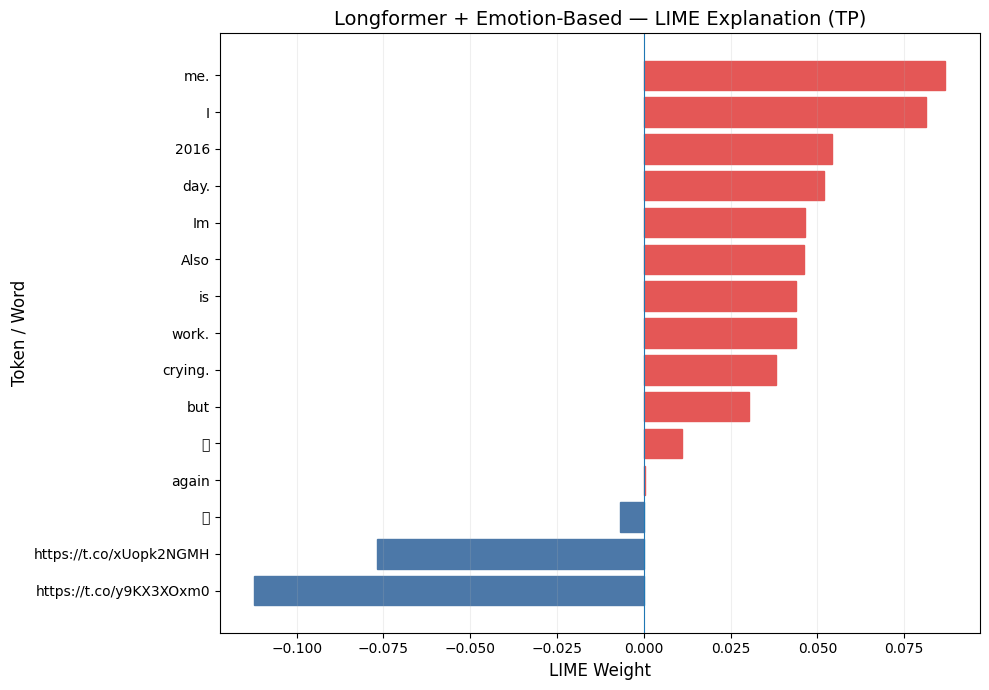

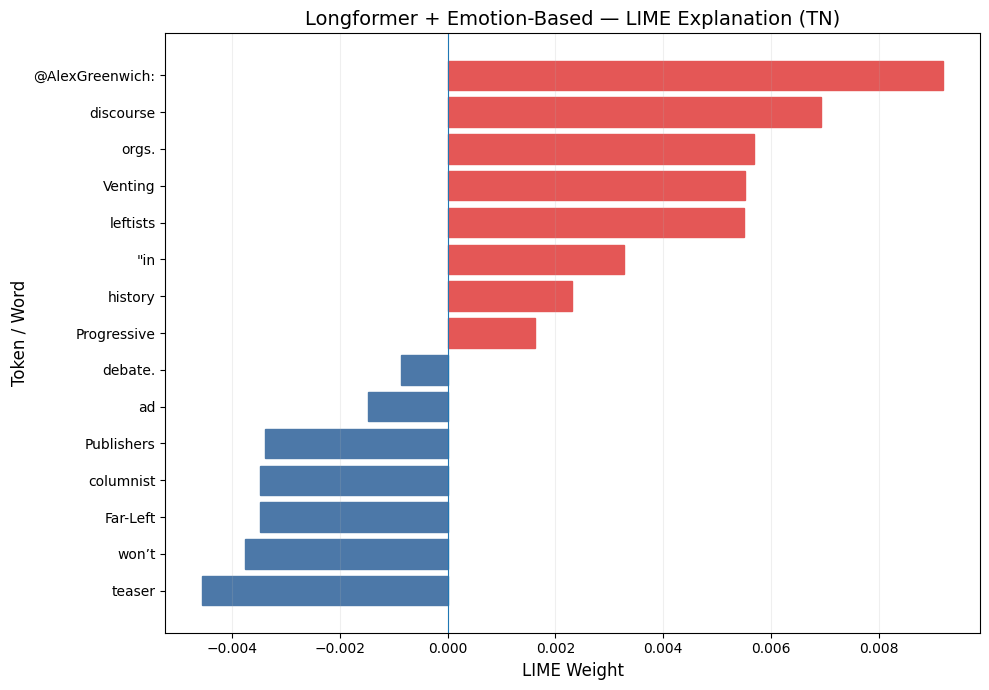

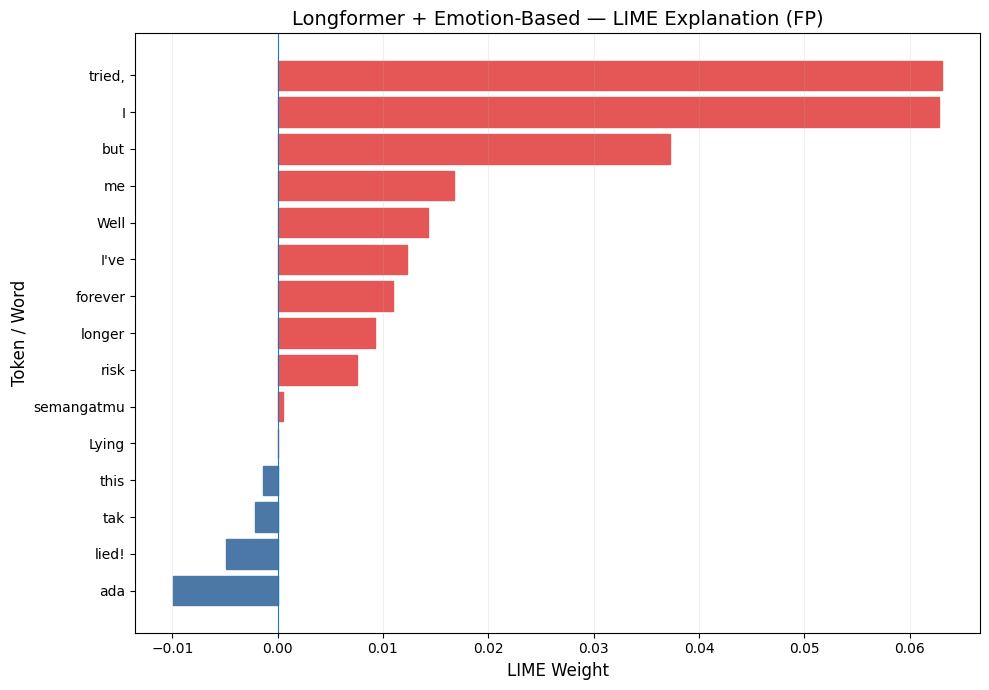

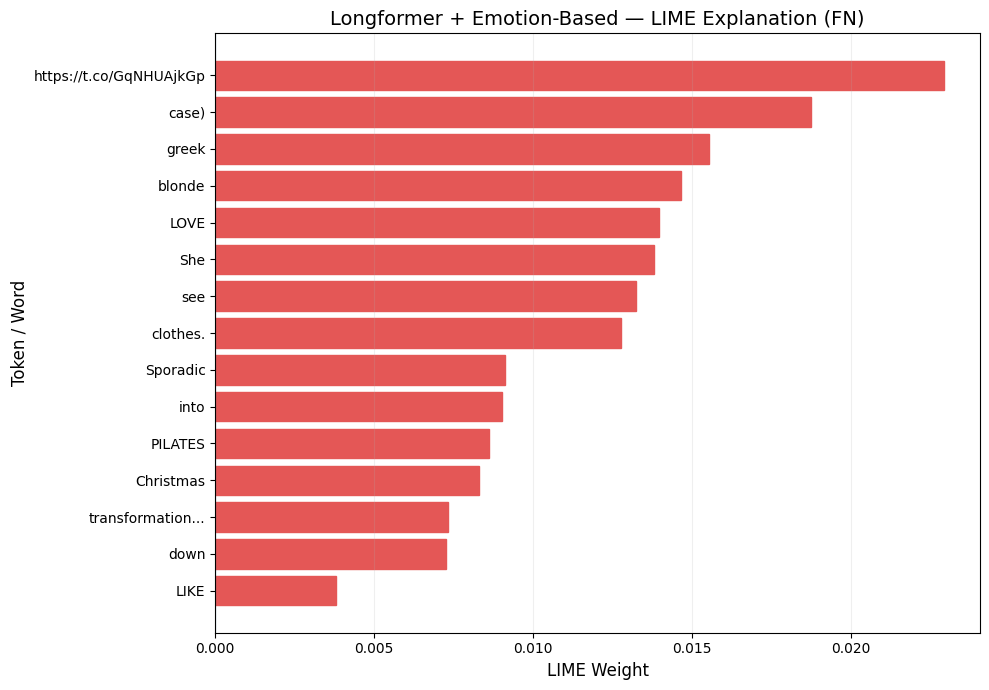


LIME ANALYSIS COMPLETE
✓ TP, TN, FP, FN cases explained
✓ Same trained Longformer Emotion-Based model used
✓ Metadata held fixed per user
✓ Emotion features held fixed per user
✓ 1000 LIME perturbations per case
✓ Top 15 features extracted
✓ LIME results saved
✓ HTML explanations saved
✓ Paper-ready LIME plots saved and displayed

LIME output directory: /kaggle/working/longformer_emotion/explainability/lime


In [22]:
# ============================================================
# EXPLAINABILITY — LIME
# LONGFORMER + EMOTION-BASED
# LOCAL TOKEN-LEVEL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML

print("=" * 70)
print("LIME ANALYSIS")
print("LONGFORMER + EMOTION-BASED")
print("=" * 70)

# ============================================================
# FIXED LIME SETTINGS
# ============================================================

LIME_SEED = 42
LIME_NUM_FEATURES = 15
LIME_NUM_SAMPLES = 1000
LIME_BATCH_SIZE = 8

np.random.seed(
    LIME_SEED
)

torch.manual_seed(
    LIME_SEED
)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

LIME_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "lime"
)

os.makedirs(
    LIME_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

print()
print(
    "✓ Longformer Emotion-Based model ready"
)

# ============================================================
# TEST PREDICTIONS
# ============================================================

labels_np = []
preds_np = []
probs_np = []

with torch.no_grad():

    for batch in test_loader:

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        emotions = (
            batch["emotions"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata,
            emotions=emotions
        )

        logits = outputs[
            "logits"
        ]

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).long()

        labels_np.extend(
            labels.cpu()
            .numpy()
            .tolist()
        )

        preds_np.extend(
            predictions.cpu()
            .numpy()
            .tolist()
        )

        probs_np.extend(
            probabilities.cpu()
            .numpy()
            .tolist()
        )

labels_np = np.asarray(
    labels_np
)

preds_np = np.asarray(
    preds_np
)

probs_np = np.asarray(
    probs_np
)

print()
print(
    "Test users:",
    len(labels_np)
)

# ============================================================
# DETERMINISTIC TP / TN / FP / FN
# ============================================================

tp_candidates = np.where(
    (labels_np == 1) &
    (preds_np == 1)
)[0]

tn_candidates = np.where(
    (labels_np == 0) &
    (preds_np == 0)
)[0]

fp_candidates = np.where(
    (labels_np == 0) &
    (preds_np == 1)
)[0]

fn_candidates = np.where(
    (labels_np == 1) &
    (preds_np == 0)
)[0]

assert len(tp_candidates) > 0
assert len(tn_candidates) > 0
assert len(fp_candidates) > 0
assert len(fn_candidates) > 0

selected_cases = {

    "TP":
        int(
            tp_candidates[0]
        ),

    "TN":
        int(
            tn_candidates[0]
        ),

    "FP":
        int(
            fp_candidates[0]
        ),

    "FN":
        int(
            fn_candidates[0]
        )
}

print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print(
        f"{case_name}: "
        f"Test Index = {test_index} | "
        f"True = {labels_np[test_index]} | "
        f"Pred = {preds_np[test_index]} | "
        f"Positive Probability = "
        f"{probs_np[test_index]:.4f}"
    )

# ============================================================
# LIME TEXT ACCESS
# ============================================================
# The same anchor-removed text used by the
# Longformer Emotion-Based pipeline is used for LIME.
# ============================================================

def get_test_text(
    test_index
):

    return str(
        test_longformer_emotion_df.iloc[
            int(test_index)
        ]["anchor_removed_text"]
    )

# ============================================================
# LIME PREDICTOR
# ============================================================
# Text is perturbed by LIME.
# Metadata and emotion features remain fixed
# for the explained user.
# ============================================================

def make_lime_predictor(
    test_index
):

    sample = test_dataset[
        int(test_index)
    ]

    fixed_metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .float()
        .to(device)
    )

    fixed_emotions = (
        sample["emotions"]
        .unsqueeze(0)
        .float()
        .to(device)
    )

    def lime_predict(
        texts
    ):

        all_probabilities = []

        for start in range(
            0,
            len(texts),
            LIME_BATCH_SIZE
        ):

            text_batch = texts[
                start:
                start + LIME_BATCH_SIZE
            ]

            encoded = tokenizer(
                text_batch,
                max_length=MAX_LENGTH,
                truncation=True,
                padding="max_length",
                return_attention_mask=True
            )

            input_ids = torch.tensor(
                encoded["input_ids"],
                dtype=torch.long
            ).to(device)

            attention_mask = torch.tensor(
                encoded["attention_mask"],
                dtype=torch.long
            ).to(device)

            metadata_batch = (
                fixed_metadata
                .expand(
                    len(text_batch),
                    -1
                )
            )

            emotion_batch = (
                fixed_emotions
                .expand(
                    len(text_batch),
                    -1
                )
            )

            with torch.no_grad():

                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    metadata=metadata_batch,
                    emotions=emotion_batch
                )

                logits = outputs[
                    "logits"
                ]

                probabilities = torch.softmax(
                    logits.float(),
                    dim=1
                )

            all_probabilities.append(
                probabilities
                .cpu()
                .numpy()
            )

            del input_ids
            del attention_mask
            del metadata_batch
            del emotion_batch
            del outputs
            del logits
            del probabilities

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        return np.vstack(
            all_probabilities
        )

    return lime_predict

# ============================================================
# LIME EXPLAINER
# ============================================================

explainer = LimeTextExplainer(
    class_names=[
        "Negative",
        "Positive"
    ],
    split_expression=r"\s+",
    random_state=LIME_SEED
)

print()
print(
    "✓ LIME explainer ready"
)

# ============================================================
# RUN LIME FOR FOUR CASES
# ============================================================

all_explanations = {}

print()
print("=" * 70)
print("GENERATING LIME EXPLANATIONS")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )

    text = get_test_text(
        test_index
    )

    predictor = make_lime_predictor(
        test_index
    )

    explanation = explainer.explain_instance(
        text,
        predictor,
        labels=(1,),
        num_features=LIME_NUM_FEATURES,
        num_samples=LIME_NUM_SAMPLES
    )

    all_explanations[
        case_name
    ] = explanation

    print(
        f"✓ {case_name} explanation complete"
    )

# ============================================================
# SAVE LIME RESULTS
# ============================================================

all_lime_rows = []

for case_name, explanation in all_explanations.items():

    explanation_list = explanation.as_list(
        label=1
    )

    for rank, (
        word,
        weight
    ) in enumerate(
        explanation_list,
        start=1
    ):

        all_lime_rows.append({

            "case":
                case_name,

            "test_index":
                selected_cases[
                    case_name
                ],

            "true_label":
                int(
                    labels_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "predicted_label":
                int(
                    preds_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "positive_probability":
                float(
                    probs_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "rank":
                rank,

            "word":
                word,

            "lime_weight":
                float(weight)

        })

lime_results_df = pd.DataFrame(
    all_lime_rows
)

lime_csv_path = os.path.join(
    LIME_DIR,
    "longformer_emotion_lime_results.csv"
)

lime_results_df.to_csv(
    lime_csv_path,
    index=False
)

# ============================================================
# DISPLAY + SAVE HTML
# ============================================================

print()
print("=" * 70)
print("LIME EXPLANATIONS")
print("=" * 70)

for case_name, explanation in all_explanations.items():

    print()
    print(
        "=" * 60
    )

    print(
        f"{case_name} — "
        f"LIME LOCAL EXPLANATION"
    )

    print(
        "=" * 60
    )

    display(
        HTML(
            explanation.as_html(
                labels=[1]
            )
        )
    )

    html_path = os.path.join(
        LIME_DIR,
        f"longformer_emotion_lime_{case_name}.html"
    )

    with open(
        html_path,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(
            explanation.as_html(
                labels=[1]
            )
        )

# ============================================================
# PAPER-FRIENDLY LIME BAR PLOTS
# ============================================================

for case_name, explanation in all_explanations.items():

    explanation_list = explanation.as_list(
        label=1
    )

    plot_df = pd.DataFrame(
        explanation_list,
        columns=[
            "word",
            "weight"
        ]
    )

    plot_df = plot_df.sort_values(
        "weight"
    )

    plt.figure(
        figsize=(10, 7)
    )

    bars = plt.barh(
        plot_df["word"],
        plot_df["weight"]
    )

    for bar, weight in zip(
        bars,
        plot_df["weight"]
    ):

        if weight > 0:

            bar.set_color(
                "#E45756"
            )

        else:

            bar.set_color(
                "#4C78A8"
            )

    plt.axvline(
        0,
        linewidth=0.8
    )

    plt.xlabel(
        "LIME Weight",
        fontsize=12
    )

    plt.ylabel(
        "Token / Word",
        fontsize=12
    )

    plt.title(
        f"Longformer + Emotion-Based — "
        f"LIME Explanation ({case_name})",
        fontsize=14
    )

    plt.grid(
        axis="x",
        alpha=0.20
    )

    plt.tight_layout()

    plot_path = os.path.join(
        LIME_DIR,
        f"longformer_emotion_lime_{case_name}.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

# ============================================================
# SAVE CASE INFORMATION
# ============================================================

case_info_rows = []

for case_name, test_index in selected_cases.items():

    case_info_rows.append({

        "case":
            case_name,

        "test_index":
            int(test_index),

        "true_label":
            int(
                labels_np[
                    test_index
                ]
            ),

        "predicted_label":
            int(
                preds_np[
                    test_index
                ]
            ),

        "positive_probability":
            float(
                probs_np[
                    test_index
                ]
            ),

        "text_length_characters":
            len(
                get_test_text(
                    test_index
                )
            )

    })

case_info_df = pd.DataFrame(
    case_info_rows
)

case_info_df.to_csv(
    os.path.join(
        LIME_DIR,
        "longformer_emotion_lime_case_information.csv"
    ),
    index=False
)

# ============================================================
# SAVE CONFIGURATION
# ============================================================

lime_config = {

    "model":
        "Longformer",

    "cleaning":
        "Emotion-Based",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class",

    "representative_cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "random_seed":
        LIME_SEED,

    "num_samples":
        LIME_NUM_SAMPLES,

    "num_features":
        LIME_NUM_FEATURES,

    "batch_size":
        LIME_BATCH_SIZE,

    "metadata":
        "Fixed for each explained user",

    "emotion_features":
        "Fixed for each explained user",

    "text_perturbation":
        "LIME word-level perturbations",

    "model_training":
        "No additional training"
}

with open(
    os.path.join(
        LIME_DIR,
        "longformer_emotion_lime_config.json"
    ),
    "w"
) as f:

    json.dump(
        lime_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("LIME ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Same trained Longformer Emotion-Based model used"
)

print(
    "✓ Metadata held fixed per user"
)

print(
    "✓ Emotion features held fixed per user"
)

print(
    "✓ 1000 LIME perturbations per case"
)

print(
    "✓ Top 15 features extracted"
)

print(
    "✓ LIME results saved"
)

print(
    "✓ HTML explanations saved"
)

print(
    "✓ Paper-ready LIME plots saved and displayed"
)

print()
print(
    "LIME output directory:",
    LIME_DIR
)